# Phase 1 — Setup & Data Understanding

In [2]:
# Core
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Housekeeping
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)   # show all 23 columns
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

print("pandas:", pd.__version__, "| numpy:", np.__version__)

pandas: 2.3.3 | numpy: 2.3.4


In [4]:
# Notebook lives in notebooks/, so project root is one level up
PROJECT_ROOT = Path.cwd().parent
DATA_RAW = PROJECT_ROOT / "data" / "raw" / "india_housing_prices.csv"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("CSV exists?  ", DATA_RAW.exists())

Project root: U:\AI\Labmentrix\Real-Estate-Investment-Advisor
CSV exists?   True


In [5]:
df = pd.read_csv(DATA_RAW)
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Shape: 250,000 rows × 23 columns


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  object 
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors    

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,250000.00,125000.50,72168.93,1.00,62500.75,125000.50,187500.25,250000.00
BHK,250000.00,3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.00,2749.81,1300.61,500.00,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.00,254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.00,0.13,0.13,0.00,0.05,0.09,0.16,0.99
Year_Built,250000.00,2006.52,9.81,1990.00,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.00,14.97,8.95,0.00,7.00,15.00,23.00,30.00
Total_Floors,250000.00,15.50,8.67,1.00,8.00,15.00,23.00,30.00
Age_of_Property,250000.00,18.48,9.81,2.00,10.00,18.00,27.00,35.00
Nearby_Schools,250000.00,5.50,2.88,1.00,3.00,5.00,8.00,10.00


In [8]:
df.describe(include="object").T

,count,unique,top,freq
State,250000,20,Odisha,12681
City,250000,42,Coimbatore,6461
Locality,250000,500,Locality_296,567
Property_Type,250000,3,Villa,83744
Furnished_Status,250000,3,Unfurnished,83408
Public_Transport_Accessibility,250000,3,High,83705
Parking_Space,250000,2,No,125456
Security,250000,2,Yes,125233
Amenities,250000,325,Pool,10218
Facing,250000,4,West,62757


In [9]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().any() else "None ✅")

print("\nFull-row duplicates:     ", df.duplicated().sum())
print("Duplicates ignoring ID:  ", df.drop(columns="ID").duplicated().sum())
print("Duplicate IDs:           ", df["ID"].duplicated().sum())

Missing values per column:
None ✅

Full-row duplicates:      0
Duplicates ignoring ID:   0
Duplicate IDs:            0


In [10]:
num_cols = df.select_dtypes(include="number").columns.drop("ID").tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()

print(f"Numeric ({len(num_cols)}):", num_cols)
print(f"\nCategorical ({len(cat_cols)}):", cat_cols)

# Unique values for low-cardinality categoricals
for col in cat_cols:
    if df[col].nunique() <= 5:
        print(f"\n{col}: {df[col].unique().tolist()}")

Numeric (10): ['BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals']

Categorical (12): ['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

Property_Type: ['Apartment', 'Independent House', 'Villa']

Furnished_Status: ['Furnished', 'Unfurnished', 'Semi-furnished']

Public_Transport_Accessibility: ['High', 'Low', 'Medium']

Parking_Space: ['No', 'Yes']

Security: ['No', 'Yes']

Facing: ['West', 'North', 'South', 'East']

Owner_Type: ['Owner', 'Builder', 'Broker']

Availability_Status: ['Ready_to_Move', 'Under_Construction']


In [11]:
# 1. Price_per_SqFt unit + rounding damage
recomputed = df["Price_in_Lakhs"] / df["Size_in_SqFt"]
print("Max diff (stored vs recomputed, lakhs):", (recomputed - df["Price_per_SqFt"]).abs().max().round(4))
print("Rows where Price_per_SqFt rounded to 0:", (df["Price_per_SqFt"] == 0).sum())

# 2. Impossible floors
bad_floor = df["Floor_No"] > df["Total_Floors"]
print(f"\nFloor_No > Total_Floors: {bad_floor.sum():,} rows ({bad_floor.mean():.1%})")

# 3. Age consistency → which reference year?
print("\nReference year(s) used for Age:", (df["Year_Built"] + df["Age_of_Property"]).unique())

# 4. Locality repeats across cities?
print("\nCities per locality:", df.groupby("Locality")["City"].nunique().describe()[["min", "max"]].tolist())

# 5. Amenities: raw strings vs real combinations
amen_sets = df["Amenities"].str.split(", ").apply(lambda x: tuple(sorted(x)))
print(f"\nAmenities → raw strings: {df['Amenities'].nunique()}, real combos: {amen_sets.nunique()}")

Max diff (stored vs recomputed, lakhs): 0.005
Rows where Price_per_SqFt rounded to 0: 2534

Floor_No > Total_Floors: 116,304 rows (46.5%)

Reference year(s) used for Age: [2025]

Cities per locality: [41.0, 42.0]

Amenities → raw strings: 325, real combos: 31


# Phase 2 — Data Preprocessing & Cleaning

In [12]:
df_clean = df.copy()

# No missing values today, but the app/pipeline may receive them later.
# Strategy: median for numeric (robust to skew), mode for categorical.
def impute(frame, num_cols, cat_cols):
    frame = frame.copy()
    for c in num_cols:
        frame[c] = frame[c].fillna(frame[c].median())
    for c in cat_cols:
        frame[c] = frame[c].fillna(frame[c].mode()[0])
    return frame

df_clean = impute(df_clean, num_cols, cat_cols)
df_clean = df_clean.drop_duplicates(subset=df_clean.columns.drop("ID"))
print("Shape after impute + dedup:", df_clean.shape)

Shape after impute + dedup: (250000, 23)


In [13]:
df_clean["Price_per_SqFt"] = (df_clean["Price_in_Lakhs"] * 1e5 / df_clean["Size_in_SqFt"]).round(2)

print("Zeros now:", (df_clean["Price_per_SqFt"] == 0).sum())
df_clean["Price_per_SqFt"].describe()

Zeros now: 0


count   250000.00
mean     13058.28
std      13071.85
min        202.25
25%       4802.84
50%       9244.75
75%      15987.39
max      99182.00
Name: Price_per_SqFt, dtype: float64

In [14]:
df_clean["Floor_Inconsistent"] = (df_clean["Floor_No"] > df_clean["Total_Floors"]).astype(int)
df_clean["Floor_No"] = np.minimum(df_clean["Floor_No"], df_clean["Total_Floors"])

print("Flagged rows:       ", df_clean["Floor_Inconsistent"].sum())
print("Remaining bad rows: ", (df_clean["Floor_No"] > df_clean["Total_Floors"]).sum())

Flagged rows:        116304
Remaining bad rows:  0


In [15]:
df_clean["City_Locality"] = df_clean["City"] + "_" + df_clean["Locality"]
print("Locality alone:  ", df_clean["Locality"].nunique())
print("City_Locality:   ", df_clean["City_Locality"].nunique())

Locality alone:   500
City_Locality:    20999


In [16]:
yes_no = {"Yes": 1, "No": 0}
df_clean["Parking_Space"] = df_clean["Parking_Space"].map(yes_no)
df_clean["Security"] = df_clean["Security"].map(yes_no)
df_clean["Is_Ready_To_Move"] = (df_clean["Availability_Status"] == "Ready_to_Move").astype(int)

# map() silently produces NaN for unexpected values — catch that
assert df_clean[["Parking_Space", "Security"]].isnull().sum().sum() == 0, "Unmapped values found!"
df_clean[["Parking_Space", "Security", "Availability_Status", "Is_Ready_To_Move"]].head()

,Parking_Space,Security,Availability_Status,Is_Ready_To_Move
0,0,0,Ready_to_Move,1
1,0,1,Under_Construction,0
2,1,0,Ready_to_Move,1
3,1,1,Ready_to_Move,1
4,0,1,Ready_to_Move,1


In [17]:
amenity_list = ["Gym", "Pool", "Clubhouse", "Garden", "Playground"]

amen_split = df_clean["Amenities"].str.split(", ")
for a in amenity_list:
    df_clean[f"Has_{a}"] = amen_split.apply(lambda x: int(a in x))

df_clean["Amenity_Count"] = df_clean[[f"Has_{a}" for a in amenity_list]].sum(axis=1)

# Sanity: count should match number of items in the original string
assert (df_clean["Amenity_Count"] == amen_split.str.len()).all()
df_clean[["Amenities"] + [f"Has_{a}" for a in amenity_list] + ["Amenity_Count"]].head()

,Amenities,Has_Gym,Has_Pool,Has_Clubhouse,Has_Garden,Has_Playground,Amenity_Count
0,"Playground, Gym, Garden, Pool, Clubhouse",1,1,1,1,1,5
1,"Playground, Clubhouse, Pool, Gym, Garden",1,1,1,1,1,5
2,"Clubhouse, Pool, Playground, Gym",1,1,1,0,1,4
3,"Playground, Clubhouse, Gym, Pool, Garden",1,1,1,1,1,5
4,"Playground, Garden, Gym, Pool, Clubhouse",1,1,1,1,1,5


Price_in_Lakhs   outliers: 0
Size_in_SqFt     outliers: 0
Price_per_SqFt   outliers: 19,723


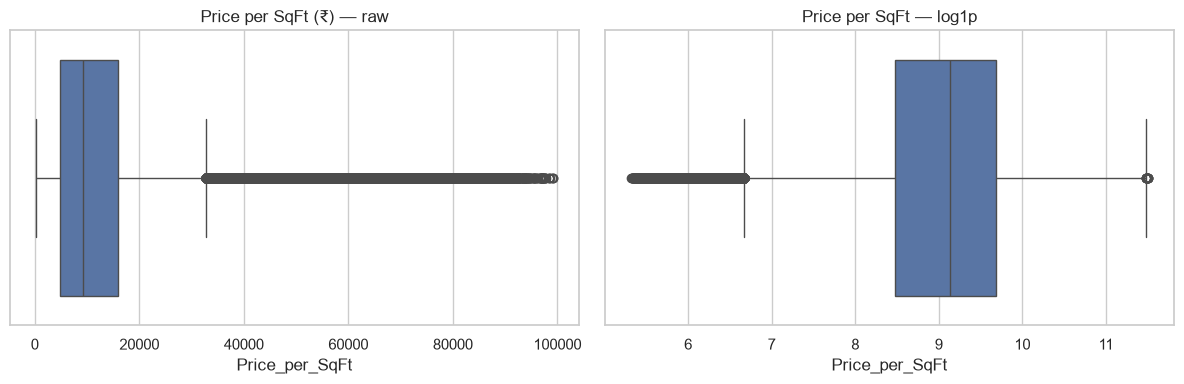

In [18]:
def iqr_flag(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - k * iqr) | (series > q3 + k * iqr)).astype(int)

for c in ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt"]:
    print(f"{c:16s} outliers: {iqr_flag(df_clean[c]).sum():,}")

df_clean["PPS_Outlier"] = iqr_flag(df_clean["Price_per_SqFt"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_clean["Price_per_SqFt"], ax=axes[0]).set_title("Price per SqFt (₹) — raw")
sns.boxplot(x=np.log1p(df_clean["Price_per_SqFt"]), ax=axes[1]).set_title("Price per SqFt — log1p")
plt.tight_layout(); plt.show()

In [19]:
print("Shape:", df_clean.shape)
print("Nulls:", df_clean.isnull().sum().sum())
print("New columns:", [c for c in df_clean.columns if c not in df.columns])

out_path = DATA_PROCESSED / "india_housing_cleaned.csv"
df_clean.to_csv(out_path, index=False)
print("Saved →", out_path)

Shape: (250000, 33)
Nulls: 0
New columns: ['Floor_Inconsistent', 'City_Locality', 'Is_Ready_To_Move', 'Has_Gym', 'Has_Pool', 'Has_Clubhouse', 'Has_Garden', 'Has_Playground', 'Amenity_Count', 'PPS_Outlier']
Saved → U:\AI\Labmentrix\Real-Estate-Investment-Advisor\data\processed\india_housing_cleaned.csv


# Phase 3 — EDA (Q1–5: Price & Size)

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

PROJECT_ROOT = Path.cwd().parent
FIG_DIR = PROJECT_ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "india_housing_cleaned.csv")
print(df.shape)

def save(name):
    """Save current figure for documentation."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

(250000, 33)


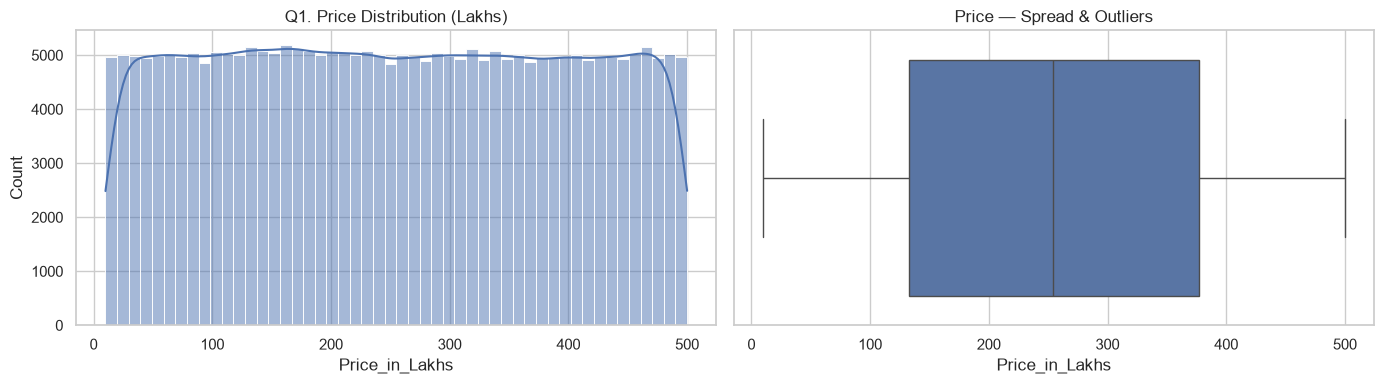

mean   254.59
50%    253.87
std    141.35
Name: Price_in_Lakhs, dtype: float64
Skew: 0.008


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["Price_in_Lakhs"], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Q1. Price Distribution (Lakhs)")

sns.boxplot(x=df["Price_in_Lakhs"], ax=ax[1])
ax[1].set_title("Price — Spread & Outliers")

plt.tight_layout(); save("q1_price_distribution"); plt.show()
print(df["Price_in_Lakhs"].describe()[["mean", "50%", "std"]])
print("Skew:", round(df["Price_in_Lakhs"].skew(), 3))

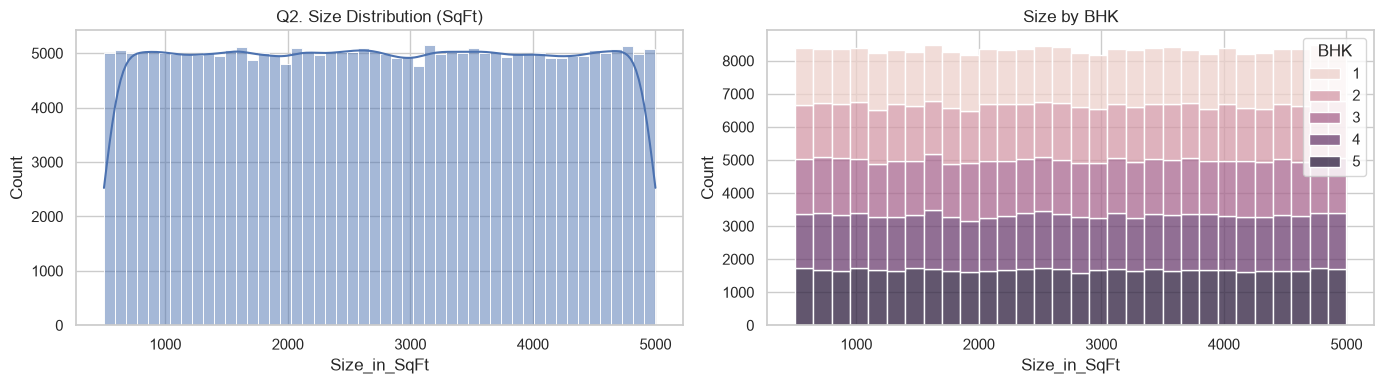

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["Size_in_SqFt"], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Q2. Size Distribution (SqFt)")

sns.histplot(data=df, x="Size_in_SqFt", hue="BHK", bins=30, multiple="stack", ax=ax[1])
ax[1].set_title("Size by BHK")

plt.tight_layout(); save("q2_size_distribution"); plt.show()

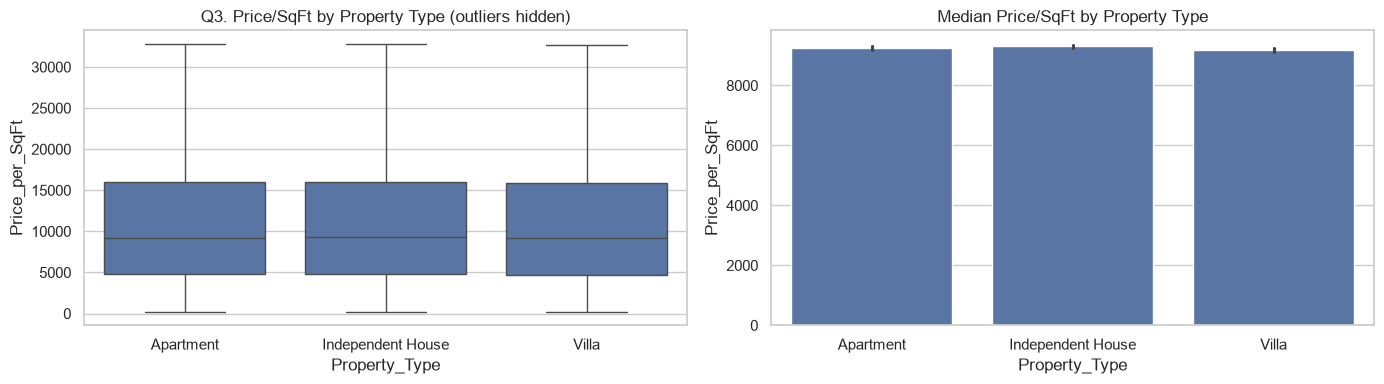

,mean,median,count
Property_Type,,,
Apartment,13047.32,9244.51,82956
Independent House,13102.05,9304.86,83300
Villa,13025.61,9190.26,83744


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt", showfliers=False, ax=ax[0])
ax[0].set_title("Q3. Price/SqFt by Property Type (outliers hidden)")

sns.barplot(data=df, x="Property_Type", y="Price_per_SqFt", estimator=np.median, ax=ax[1])
ax[1].set_title("Median Price/SqFt by Property Type")

plt.tight_layout(); save("q3_pps_by_type"); plt.show()
df.groupby("Property_Type")["Price_per_SqFt"].agg(["mean", "median", "count"])

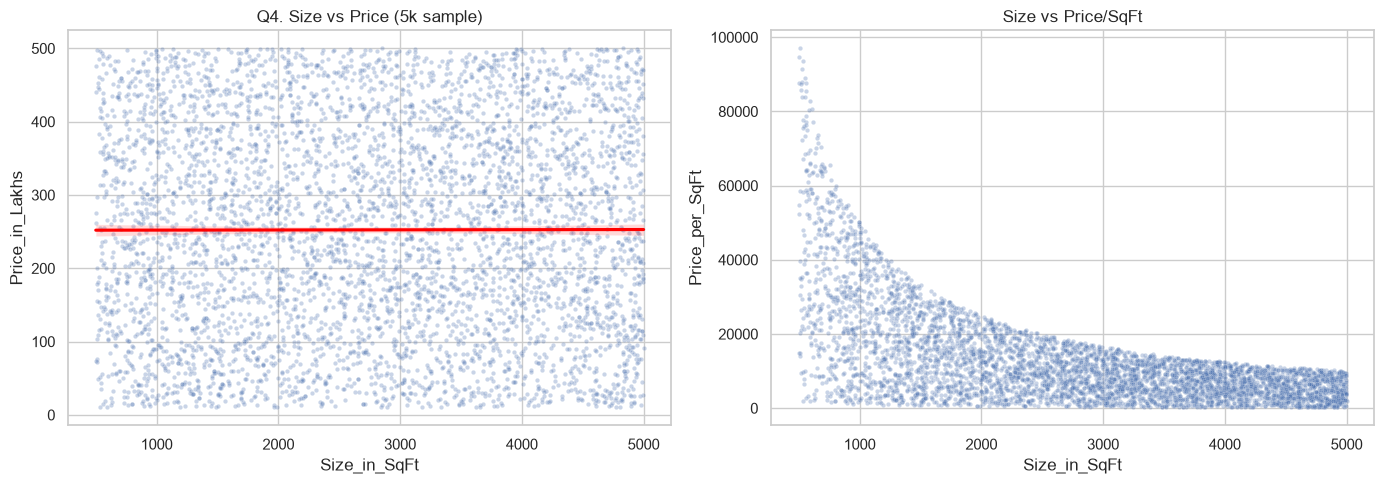

Pearson r (size, price):     -0.0025
Pearson r (size, price/sqft): -0.6146


In [24]:
sample = df.sample(5000, random_state=42)   # 250k points = unreadable blob + slow

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.3, s=10, ax=ax[0])
ax[0].set_title("Q4. Size vs Price (5k sample)")

sns.regplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs",
            scatter=False, line_kws={"color": "red"}, ax=ax[0])

sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_per_SqFt", alpha=0.3, s=10, ax=ax[1])
ax[1].set_title("Size vs Price/SqFt")

plt.tight_layout(); save("q4_size_vs_price"); plt.show()

print("Pearson r (size, price):    ", round(df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]), 4))
print("Pearson r (size, price/sqft):", round(df["Size_in_SqFt"].corr(df["Price_per_SqFt"]), 4))

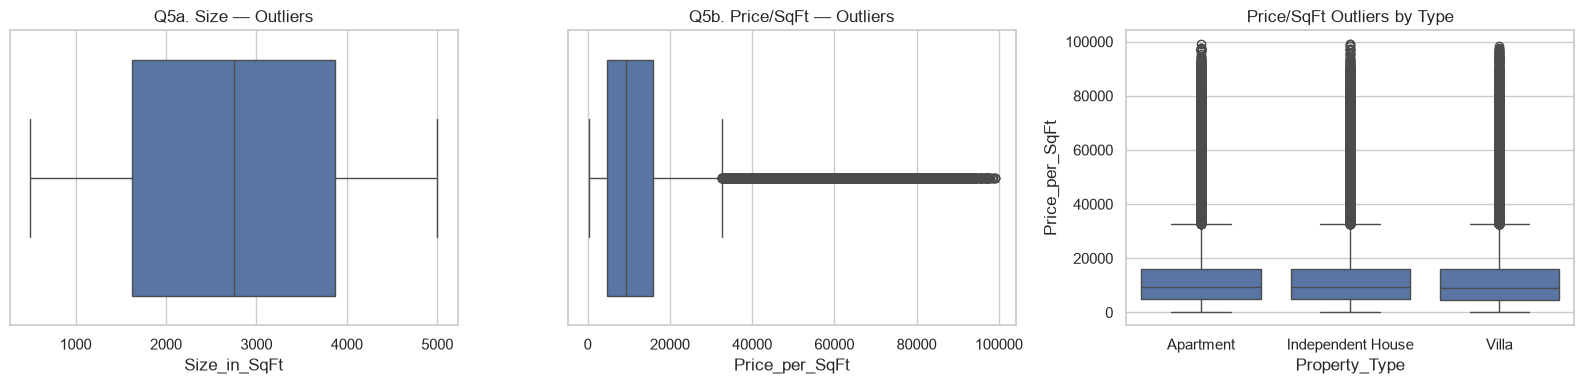

Outliers: 19,723 (7.9%)

Outliers vs all — median size & price:
                   All  Outliers
Size_in_SqFt   2747.00    799.00
Price_in_Lakhs  253.87    400.90


In [25]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(x=df["Size_in_SqFt"], ax=ax[0]).set_title("Q5a. Size — Outliers")
sns.boxplot(x=df["Price_per_SqFt"], ax=ax[1]).set_title("Q5b. Price/SqFt — Outliers")
sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt", ax=ax[2]).set_title("Price/SqFt Outliers by Type")

plt.tight_layout(); save("q5_outliers"); plt.show()

# Who are the outliers?
out = df[df["PPS_Outlier"] == 1]
print(f"Outliers: {len(out):,} ({len(out)/len(df):.1%})")
print("\nOutliers vs all — median size & price:")
print(pd.DataFrame({
    "All": df[["Size_in_SqFt", "Price_in_Lakhs"]].median(),
    "Outliers": out[["Size_in_SqFt", "Price_in_Lakhs"]].median()
}))

In [26]:
def spread(series):
    """How much do group averages differ? (max-min) as % of overall mean."""
    pct = (series.max() - series.min()) / series.mean() * 100
    print(f"Range: {series.min():,.0f} → {series.max():,.0f}  |  spread = {pct:.1f}% of mean")

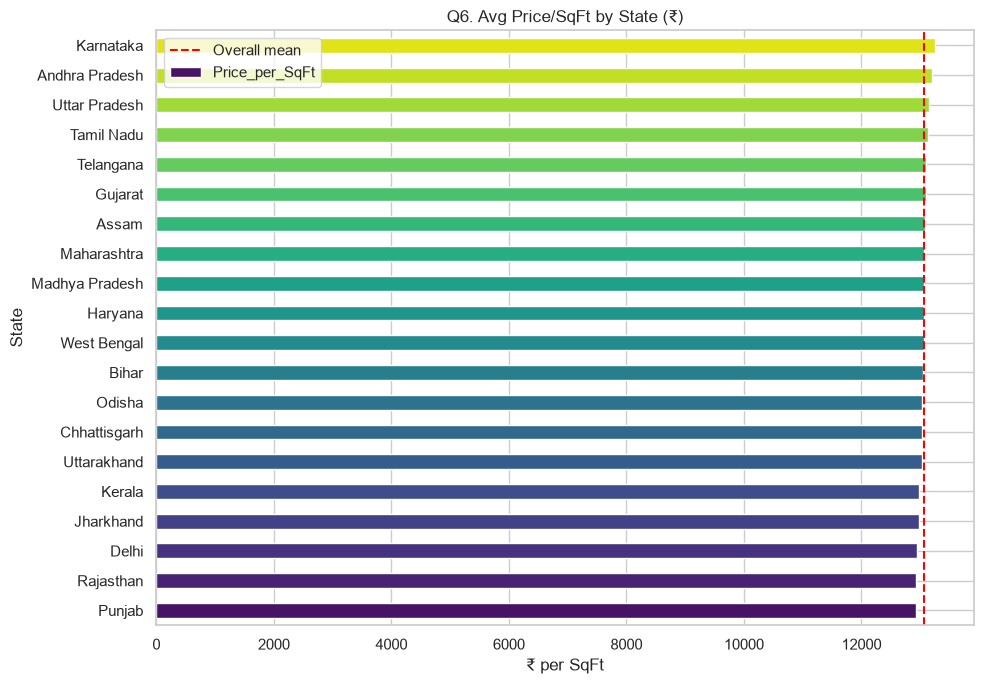

Range: 12,931 → 13,252  |  spread = 2.5% of mean


In [27]:
state_pps = df.groupby("State")["Price_per_SqFt"].mean().sort_values()

plt.figure(figsize=(10, 7))
state_pps.plot(kind="barh", color=sns.color_palette("viridis", len(state_pps)))
plt.axvline(df["Price_per_SqFt"].mean(), color="red", ls="--", label="Overall mean")
plt.title("Q6. Avg Price/SqFt by State (₹)"); plt.xlabel("₹ per SqFt"); plt.legend()
plt.tight_layout(); save("q6_pps_by_state"); plt.show()

spread(state_pps)

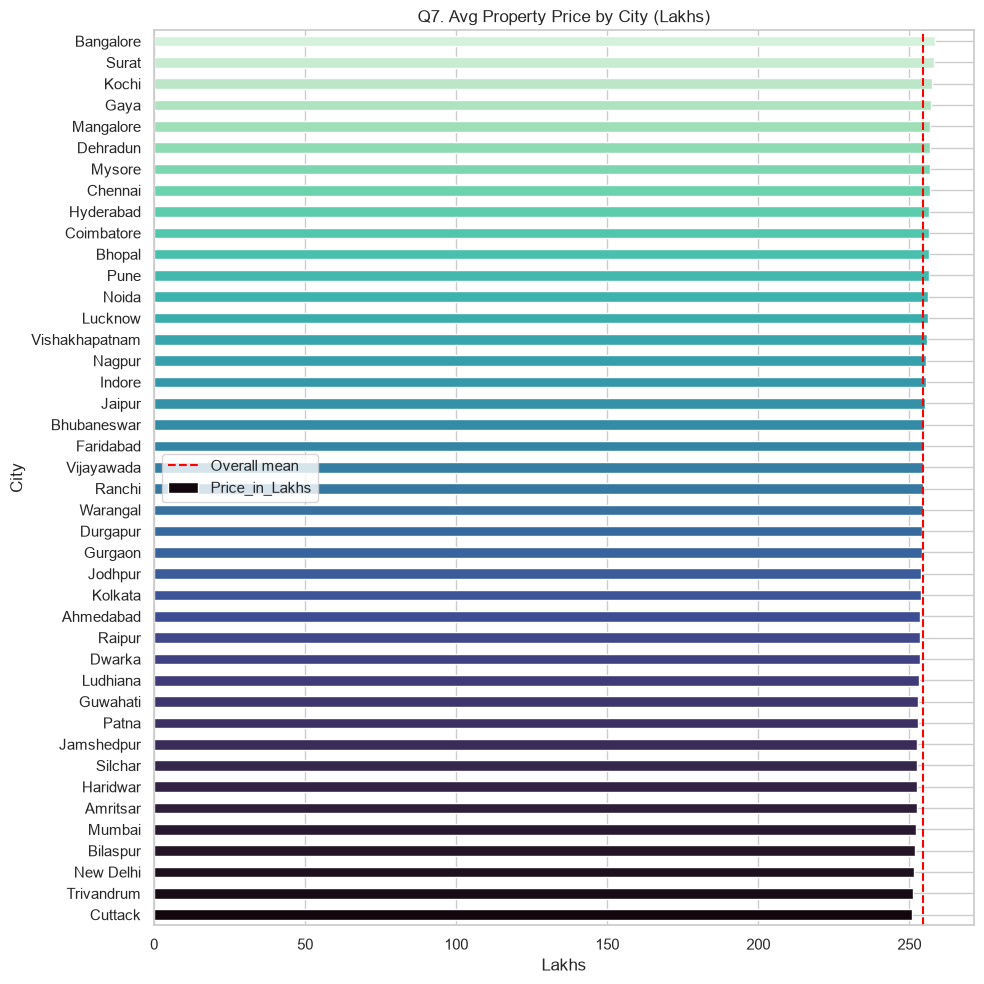

Range: 251 → 258  |  spread = 3.0% of mean

Top 5:
 City
Bangalore   258.50
Surat       258.10
Kochi       257.40
Gaya        257.10
Mangalore   256.90
Name: Price_in_Lakhs, dtype: float64

Bottom 5:
 City
Cuttack      250.80
Trivandrum   251.30
New Delhi    251.60
Bilaspur     251.90
Mumbai       252.10
Name: Price_in_Lakhs, dtype: float64


In [28]:
city_price = df.groupby("City")["Price_in_Lakhs"].mean().sort_values()

plt.figure(figsize=(10, 10))
city_price.plot(kind="barh", color=sns.color_palette("mako", len(city_price)))
plt.axvline(df["Price_in_Lakhs"].mean(), color="red", ls="--", label="Overall mean")
plt.title("Q7. Avg Property Price by City (Lakhs)"); plt.xlabel("Lakhs"); plt.legend()
plt.tight_layout(); save("q7_price_by_city"); plt.show()

spread(city_price)
print("\nTop 5:\n", city_price.tail(5)[::-1].round(1))
print("\nBottom 5:\n", city_price.head(5).round(1))

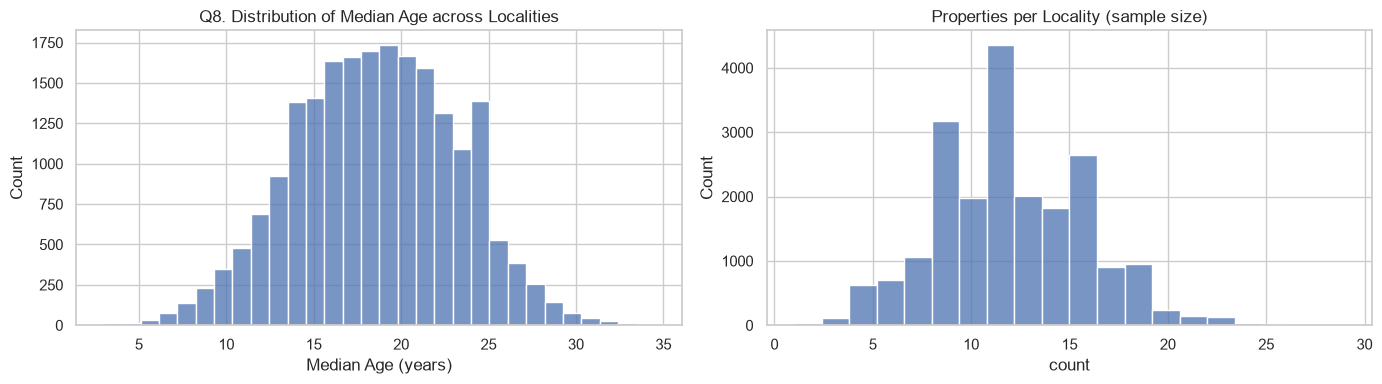

Oldest 5 localities (n ≥ 10):
                          median  count
City_Locality                         
Jaipur_Locality_249       33.00     11
Pune_Locality_439         32.00     14
Dwarka_Locality_95        32.00     11
Chennai_Locality_133      32.00     11
Coimbatore_Locality_479   31.50     12

Newest 5 localities (n ≥ 10):
                              median  count
City_Locality                             
Vishakhapatnam_Locality_133    3.00     11
Silchar_Locality_422           4.00     13
Bilaspur_Locality_215          4.00     11
New Delhi_Locality_409         4.50     10
Raipur_Locality_154            5.00     14


In [29]:
# Use City_Locality — plain Locality mixes 42 different cities together
loc_age = df.groupby("City_Locality")["Age_of_Property"].agg(["median", "count"])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(loc_age["median"], bins=30, ax=ax[0])
ax[0].set_title("Q8. Distribution of Median Age across Localities")
ax[0].set_xlabel("Median Age (years)")

sns.histplot(loc_age["count"], bins=20, ax=ax[1])
ax[1].set_title("Properties per Locality (sample size)")

plt.tight_layout(); save("q8_age_by_locality"); plt.show()

reliable = loc_age[loc_age["count"] >= 10]
print("Oldest 5 localities (n ≥ 10):\n", reliable.sort_values("median", ascending=False).head())
print("\nNewest 5 localities (n ≥ 10):\n", reliable.sort_values("median").head())

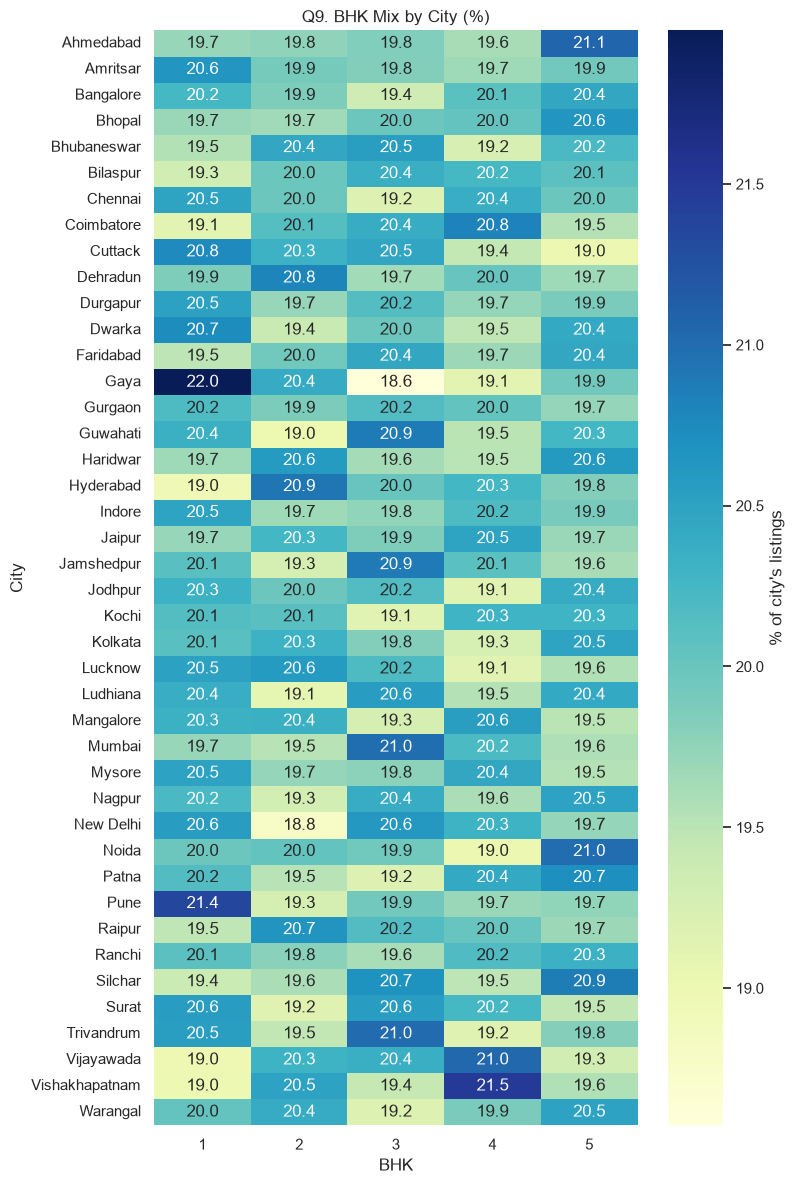

Max deviation from 20% in any cell: 1.98 pp


In [31]:
bhk_city = pd.crosstab(df["City"], df["BHK"], normalize="index") * 100

plt.figure(figsize=(8, 12))
sns.heatmap(bhk_city, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "% of city's listings"})
plt.title("Q9. BHK Mix by City (%)")
plt.tight_layout(); save("q9_bhk_by_city"); plt.show()

print("Max deviation from 20% in any cell:", round((bhk_city - 20).abs().values.max(), 2), "pp")

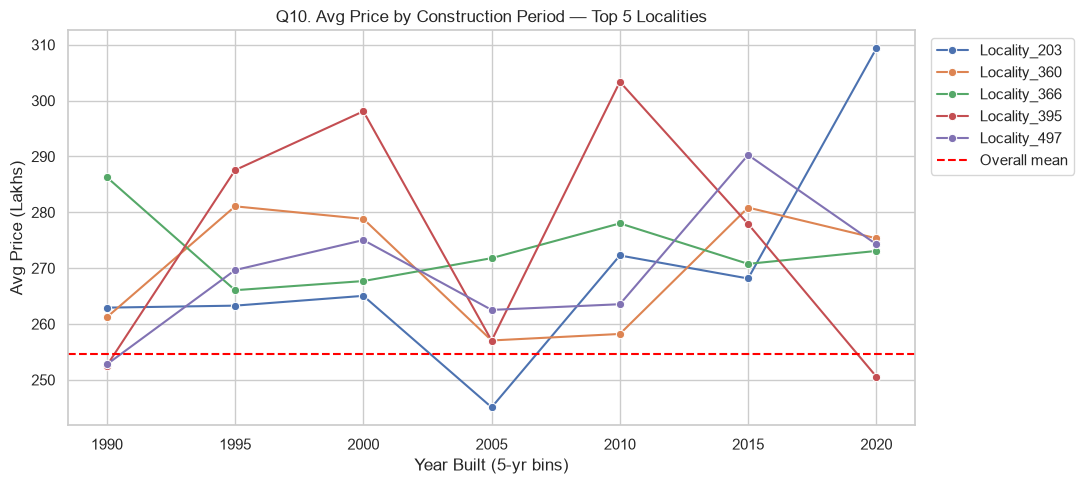

Locality
Locality_395   275.40
Locality_366   273.40
Locality_497   270.00
Locality_360   269.80
Locality_203   269.00
Name: Price_in_Lakhs, dtype: float64


In [32]:
# No date/sale-year column exists → Year_Built is the only time axis available.
# Using Locality (≈500 rows each) — City_Locality has too few rows per year for a trend.
top5 = df.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5).index
sub = df[df["Locality"].isin(top5)].copy()
sub["Built_Bin"] = (sub["Year_Built"] // 5) * 5          # 5-year buckets smooth the noise

trend = sub.groupby(["Built_Bin", "Locality"])["Price_in_Lakhs"].mean().reset_index()

plt.figure(figsize=(11, 5))
sns.lineplot(data=trend, x="Built_Bin", y="Price_in_Lakhs", hue="Locality", marker="o")
plt.axhline(df["Price_in_Lakhs"].mean(), color="red", ls="--", label="Overall mean")
plt.title("Q10. Avg Price by Construction Period — Top 5 Localities")
plt.xlabel("Year Built (5-yr bins)"); plt.ylabel("Avg Price (Lakhs)"); plt.legend(bbox_to_anchor=(1.01, 1))
plt.tight_layout(); save("q10_top5_locality_trend"); plt.show()

print(df.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5).round(1))

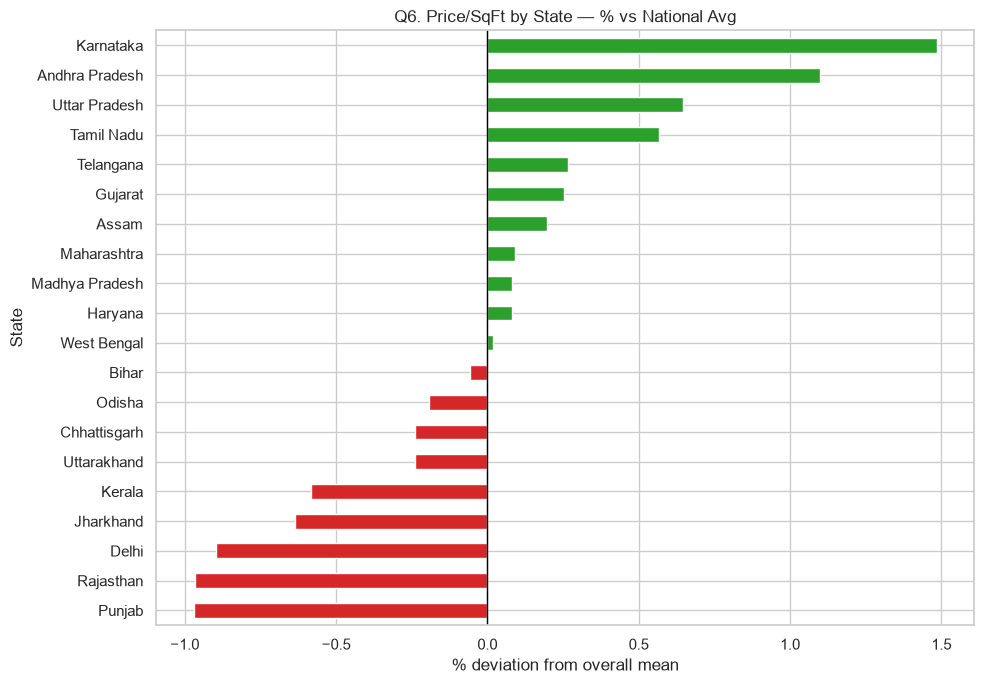

Range: 12,931 → 13,252  |  spread = 2.5% of mean


In [33]:
def deviation_plot(series, overall_mean, title, fname, figsize=(10, 7)):
    dev = ((series - overall_mean) / overall_mean * 100).sort_values()
    colors = ["#d62728" if v < 0 else "#2ca02c" for v in dev]

    plt.figure(figsize=figsize)
    dev.plot(kind="barh", color=colors)
    plt.axvline(0, color="black", lw=1)
    plt.title(title); plt.xlabel("% deviation from overall mean")
    plt.tight_layout(); save(fname); plt.show()
    spread(series)

# Q6
state_pps = df.groupby("State")["Price_per_SqFt"].mean()
deviation_plot(state_pps, df["Price_per_SqFt"].mean(),
               "Q6. Price/SqFt by State — % vs National Avg", "q6_pps_by_state")

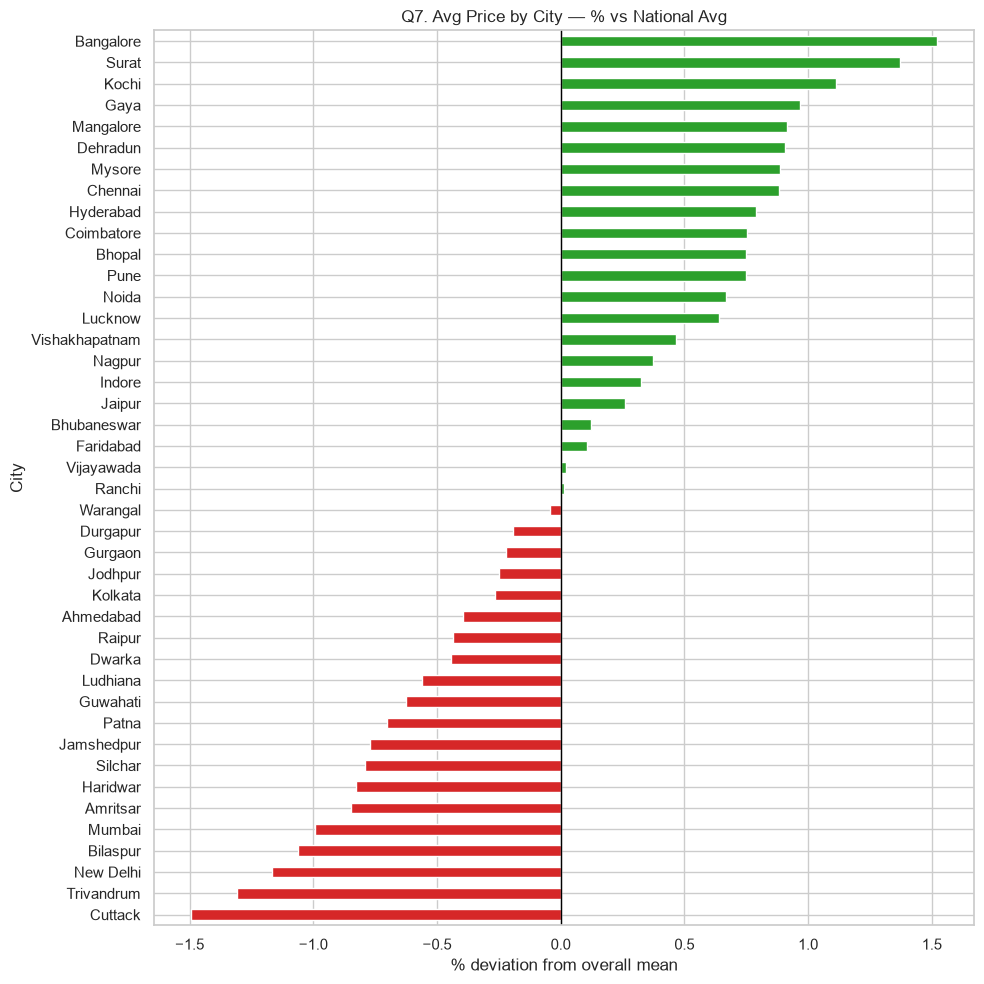

Range: 251 → 258  |  spread = 3.0% of mean


In [37]:
# Q7
city_price = df.groupby("City")["Price_in_Lakhs"].mean()
deviation_plot(city_price, df["Price_in_Lakhs"].mean(),
               "Q7. Avg Price by City — % vs National Avg", "q7_price_by_city", figsize=(10, 10))

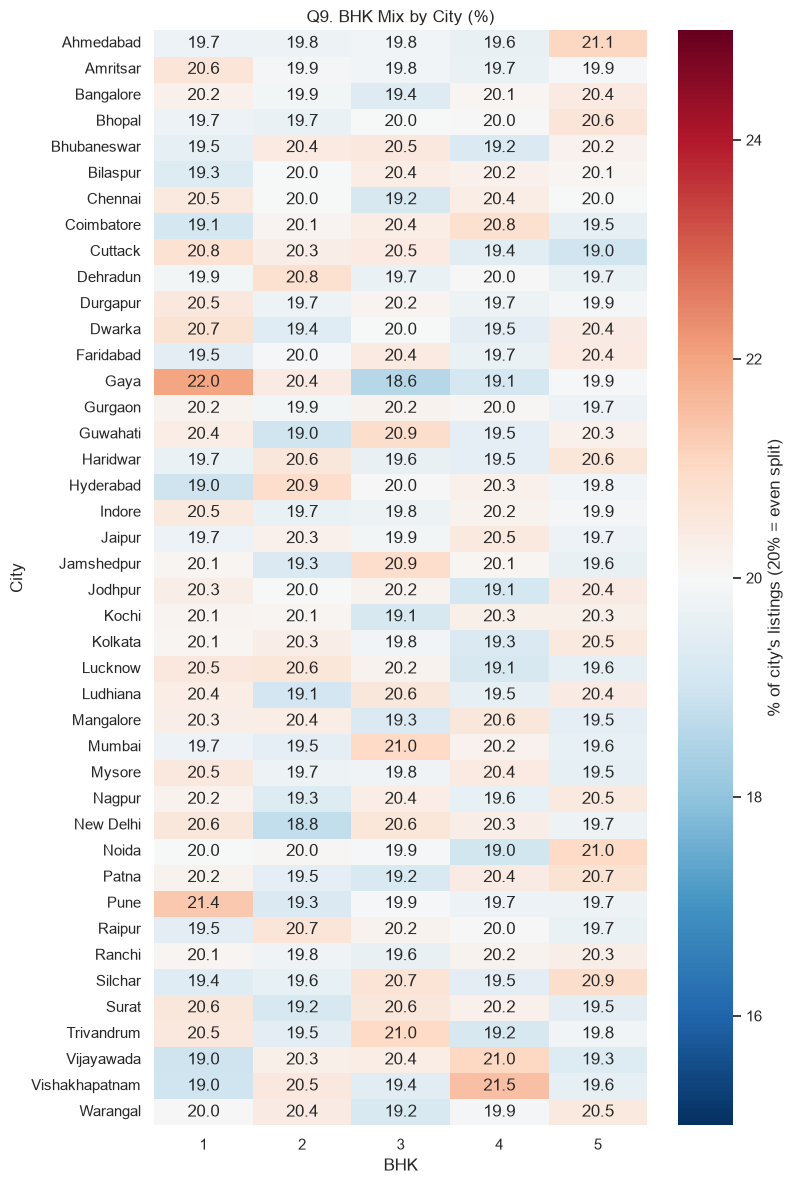

In [38]:
plt.figure(figsize=(8, 12))
sns.heatmap(bhk_city, annot=True, fmt=".1f", cmap="RdBu_r", center=20, vmin=15, vmax=25,
            cbar_kws={"label": "% of city's listings (20% = even split)"})
plt.title("Q9. BHK Mix by City (%)")
plt.tight_layout(); save("q9_bhk_by_city"); plt.show()

In [35]:
from scipy import stats

# Q6: does price/sqft differ across states? (Kruskal-Wallis: no normality assumption)
groups = [g["Price_per_SqFt"].values for _, g in df.groupby("State")]
h, p = stats.kruskal(*groups)
print(f"Q6 State vs Price/SqFt   → Kruskal H={h:.1f}, p={p:.4f}")

# Q7: does price differ across cities?
groups = [g["Price_in_Lakhs"].values for _, g in df.groupby("City")]
h, p = stats.kruskal(*groups)
print(f"Q7 City vs Price         → Kruskal H={h:.1f}, p={p:.4f}")

# Q9: is BHK mix independent of city?
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["City"], df["BHK"]))
print(f"Q9 City vs BHK           → Chi² ={chi2:.1f}, dof={dof}, p={p:.4f}")

Q6 State vs Price/SqFt   → Kruskal H=17.1, p=0.5825
Q7 City vs Price         → Kruskal H=47.5, p=0.2252
Q9 City vs BHK           → Chi² =186.5, dof=164, p=0.1098


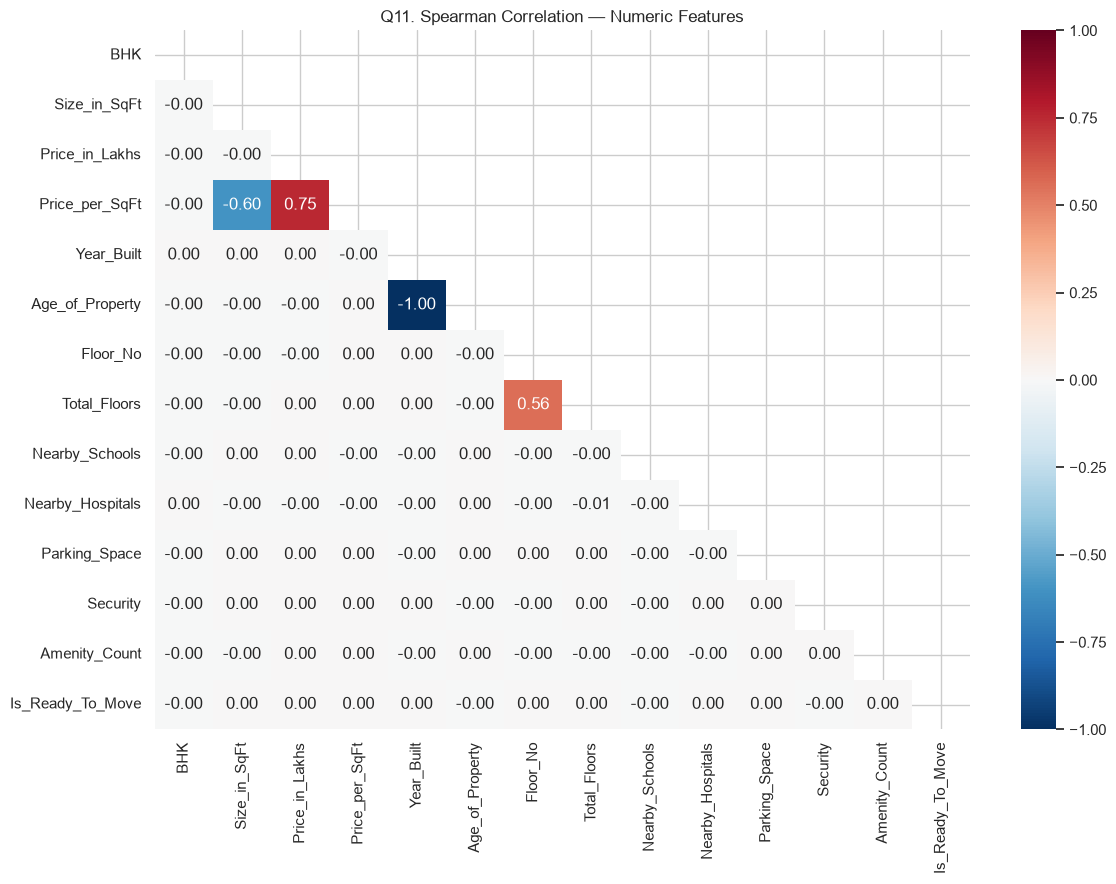

            level_0         level_1     r
14  Age_of_Property      Year_Built -1.00
5    Price_per_SqFt  Price_in_Lakhs  0.75
4    Price_per_SqFt    Size_in_SqFt -0.60
27     Total_Floors        Floor_No  0.56


In [39]:
corr_cols = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Year_Built",
             "Age_of_Property", "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals",
             "Parking_Space", "Security", "Amenity_Count", "Is_Ready_To_Move"]

corr = df[corr_cols].corr(method="spearman")   # Spearman: robust to the skewed Price_per_SqFt
mask = np.triu(np.ones_like(corr, dtype=bool))  # hide duplicate upper half

plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Q11. Spearman Correlation — Numeric Features")
plt.tight_layout(); save("q11_correlation"); plt.show()

# List every pair with |r| > 0.1
pairs = corr.where(~mask).stack().rename("r").reset_index()
print(pairs[pairs["r"].abs() > 0.1].sort_values("r", key=abs, ascending=False))

In [41]:
from scipy import stats

def category_effect(col, target="Price_per_SqFt", order=None, qnum=""):
    """Boxplot + median bar + Kruskal test + spread for one categorical/discrete feature."""
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    sns.boxplot(data=df, x=col, y=target, order=order, showfliers=False, ax=ax[0])
    ax[0].set_title(f"{qnum} {target} by {col}")

    med = df.groupby(col)[target].median()
    med = med.reindex(order) if order else med
    sns.barplot(x=med.index.astype(str), y=med.values, ax=ax[1], color="steelblue")
    ax[1].axhline(df[target].median(), color="red", ls="--", label="Overall median")
    ax[1].set_title(f"Median {target} by {col}"); ax[1].legend()

    plt.tight_layout(); save(f"{qnum.lower().rstrip('.')}_{col.lower()}"); plt.show()

    groups = [g[target].values for _, g in df.groupby(col)]
    h, p = stats.kruskal(*groups)
    pct = (med.max() - med.min()) / df[target].median() * 100
    verdict = "SIGNIFICANT" if p < 0.05 else "not significant"
    print(f"Kruskal H={h:.1f}, p={p:.4f} → {verdict}  |  median spread = {pct:.1f}%")

    if pd.api.types.is_numeric_dtype(df[col]):
        rho, p_rho = stats.spearmanr(df[col], df[target])
        print(f"Spearman ρ={rho:.4f}, p={p_rho:.4f}  (trend direction)")

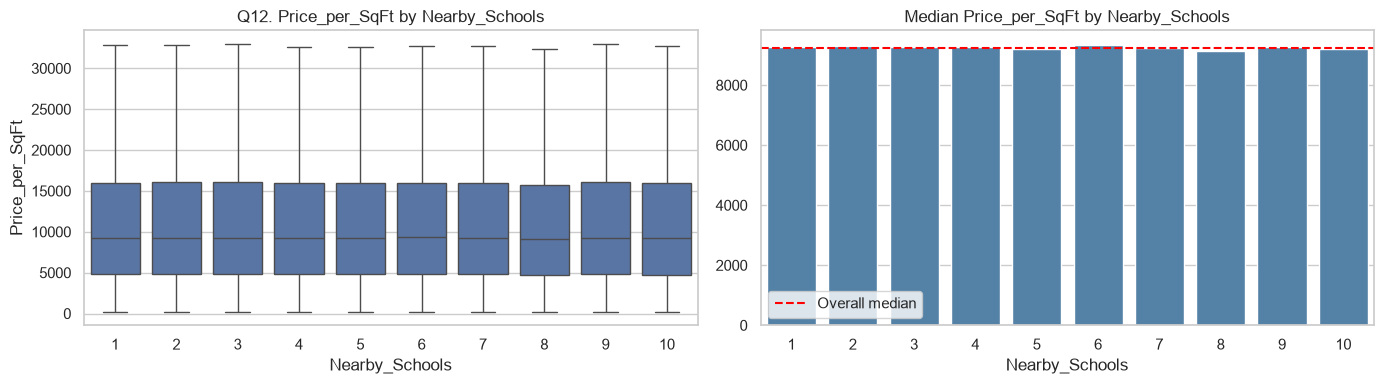

Kruskal H=13.0, p=0.1614 → not significant  |  median spread = 2.2%
Spearman ρ=-0.0023, p=0.2564  (trend direction)


In [42]:
category_effect("Nearby_Schools", qnum="Q12.")

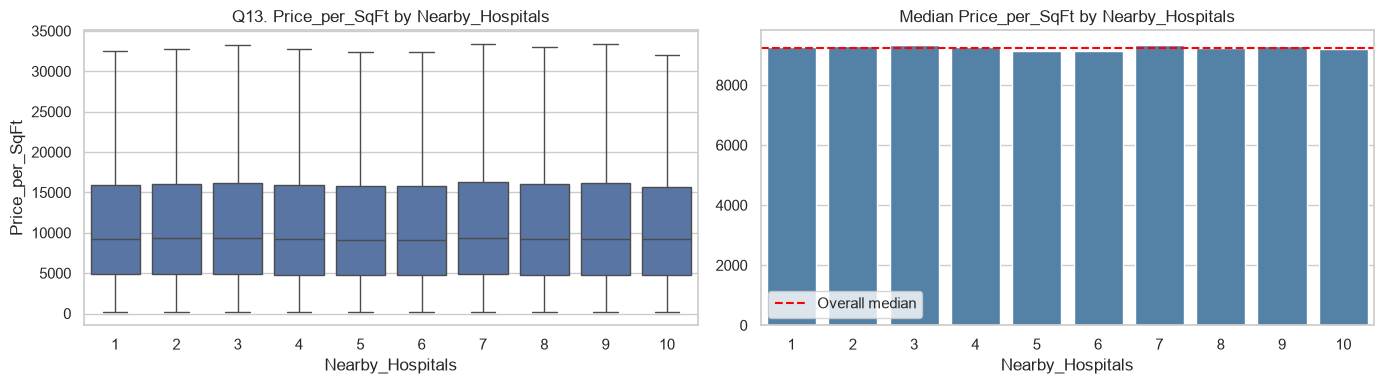

Kruskal H=16.1, p=0.0642 → not significant  |  median spread = 2.4%
Spearman ρ=-0.0017, p=0.3883  (trend direction)


In [43]:
category_effect("Nearby_Hospitals", qnum="Q13.")

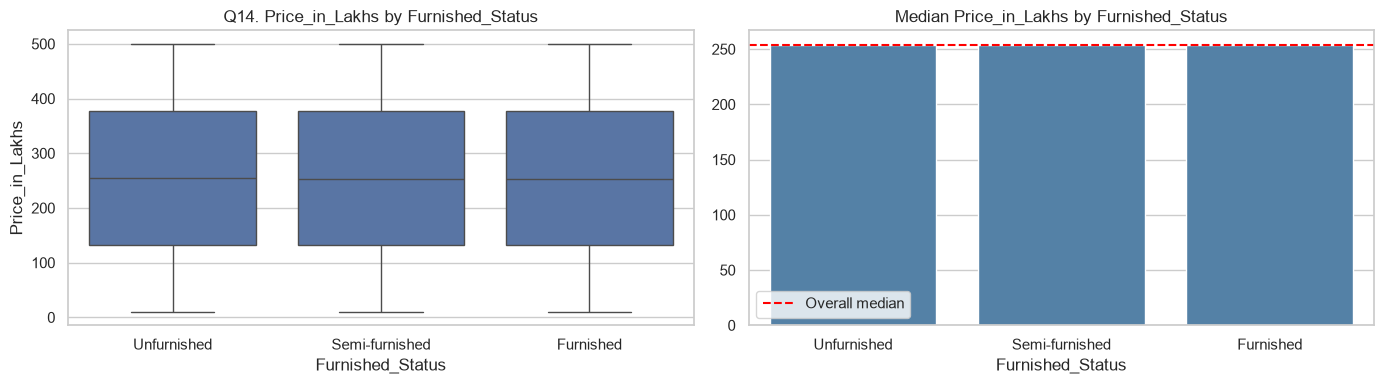

Kruskal H=1.0, p=0.6089 → not significant  |  median spread = 0.3%


In [44]:
category_effect("Furnished_Status", target="Price_in_Lakhs",
                order=["Unfurnished", "Semi-furnished", "Furnished"], qnum="Q14.")

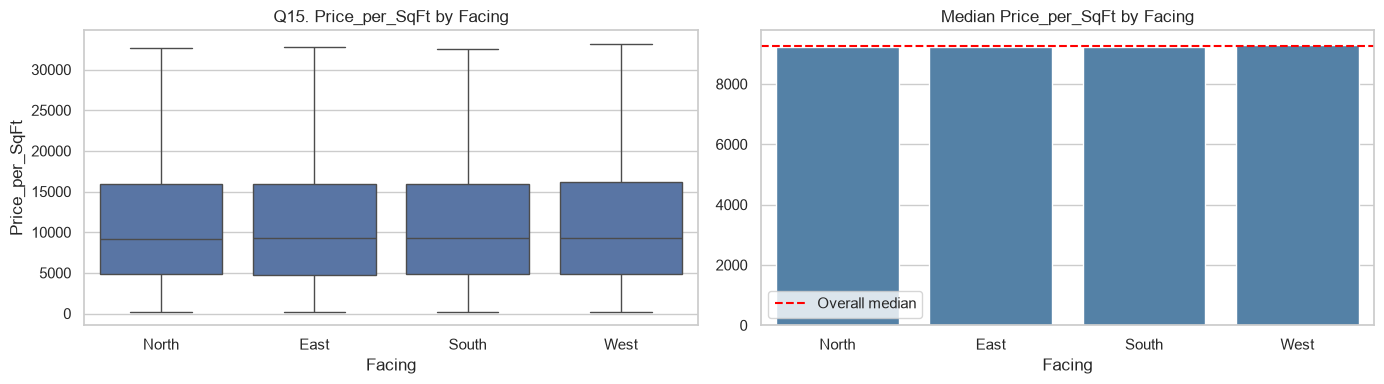

Kruskal H=3.3, p=0.3461 → not significant  |  median spread = 1.0%


In [45]:
category_effect("Facing", order=["North", "East", "South", "West"], qnum="Q15.")

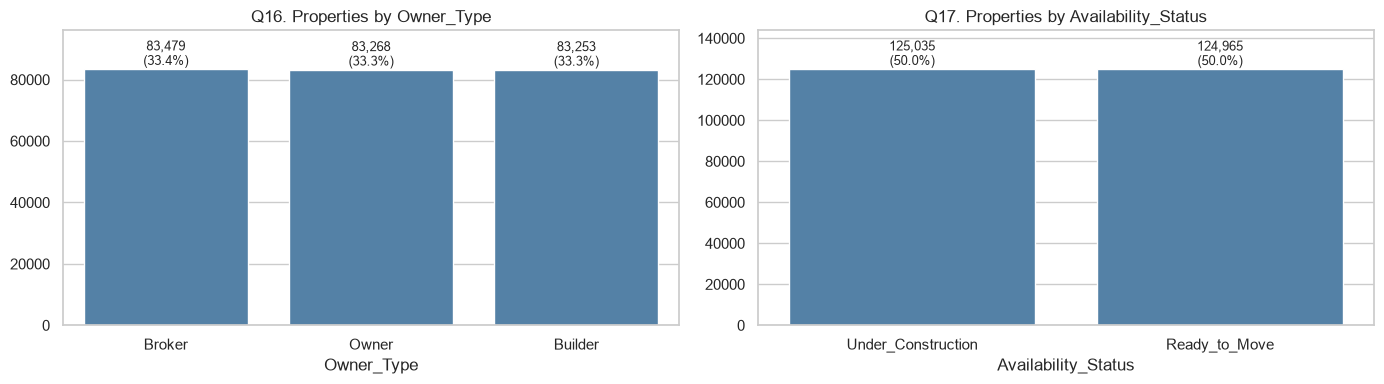

Availability_Status  Ready_to_Move  Under_Construction
Owner_Type                                            
Broker                       49.70               50.30
Builder                      50.10               49.90
Owner                        50.20               49.80

Owner_Type ↔ Availability: χ²=3.2, p=0.2016


In [46]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

for a, col, q in [(ax[0], "Owner_Type", "Q16"), (ax[1], "Availability_Status", "Q17")]:
    counts = df[col].value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=a, color="steelblue")
    a.set_title(f"{q}. Properties by {col}")
    for i, v in enumerate(counts.values):
        a.text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
    a.set_ylim(0, counts.max() * 1.15)

plt.tight_layout(); save("q16_q17_owner_availability"); plt.show()

# Do owner type and availability interact? (e.g., builders → more under-construction)
ct = pd.crosstab(df["Owner_Type"], df["Availability_Status"], normalize="index") * 100
print(ct.round(1))
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["Owner_Type"], df["Availability_Status"]))
print(f"\nOwner_Type ↔ Availability: χ²={chi2:.1f}, p={p:.4f}")

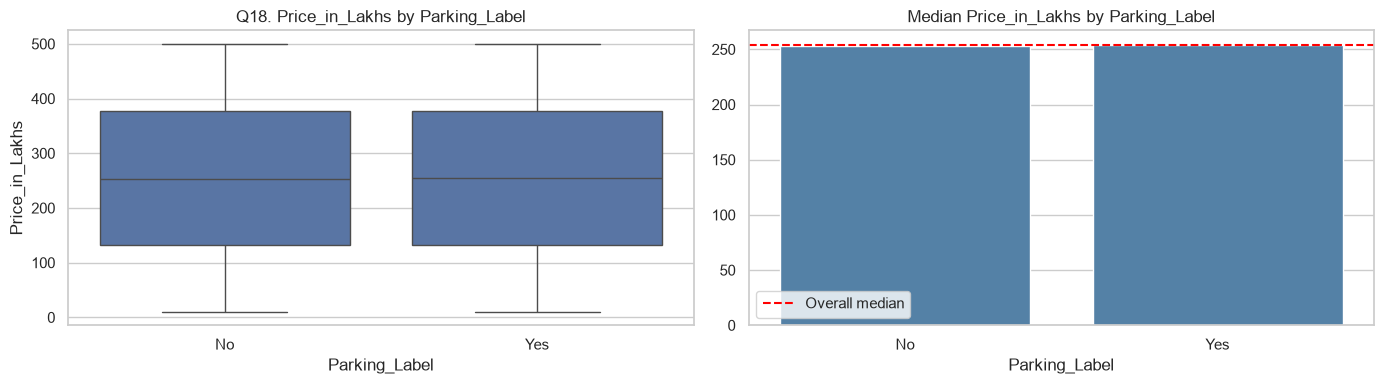

Kruskal H=0.3, p=0.5749 → not significant  |  median spread = 0.4%
Mann-Whitney U p=0.5749  |  median No=253.4 L, Yes=254.4 L


In [47]:
df["Parking_Label"] = df["Parking_Space"].map({0: "No", 1: "Yes"})
category_effect("Parking_Label", target="Price_in_Lakhs", order=["No", "Yes"], qnum="Q18.")

# Two groups → Mann-Whitney is the direct test
no, yes = [g["Price_in_Lakhs"] for _, g in df.groupby("Parking_Space")]
u, p = stats.mannwhitneyu(no, yes)
print(f"Mann-Whitney U p={p:.4f}  |  median No={no.median():.1f} L, Yes={yes.median():.1f} L")

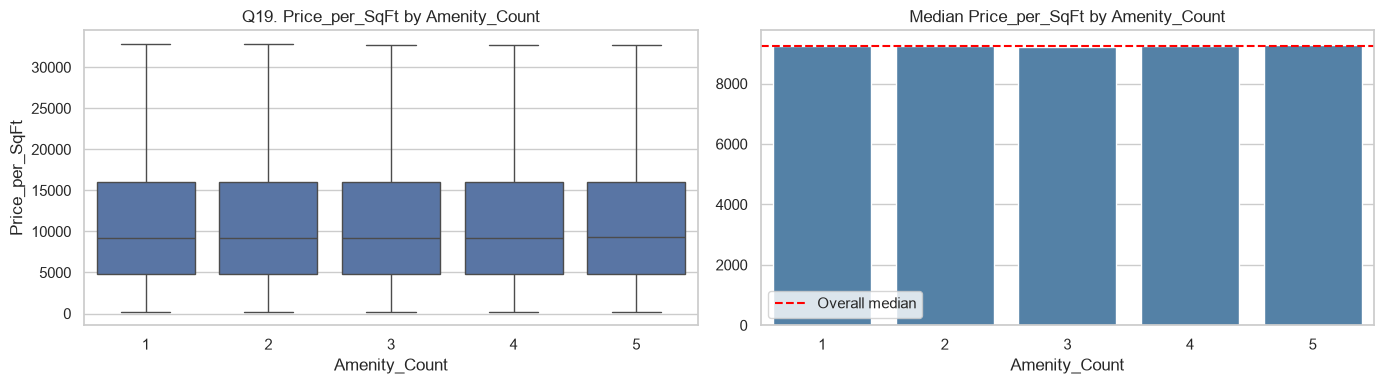

Kruskal H=3.1, p=0.5426 → not significant  |  median spread = 0.9%
Spearman ρ=0.0025, p=0.2061  (trend direction)


,With,Without,Premium_%,p_value,Share_with_%
Amenity,,,,,
Gym,9268.70,9222.76,0.50,0.02,59.98
Pool,9249.32,9241.12,0.09,0.37,60.04
Clubhouse,9242.13,9249.59,-0.08,0.92,60.02
Garden,9247.11,9241.51,0.06,0.73,60.07
Playground,9260.12,9228.97,0.34,0.99,59.91


In [48]:
# (a) Overall: does having MORE amenities help?
category_effect("Amenity_Count", qnum="Q19.")

# (b) Individually: which amenity, if any, carries a premium?
rows = []
for a in ["Gym", "Pool", "Clubhouse", "Garden", "Playground"]:
    has, hasnt = df.loc[df[f"Has_{a}"] == 1, "Price_per_SqFt"], df.loc[df[f"Has_{a}"] == 0, "Price_per_SqFt"]
    _, p = stats.mannwhitneyu(has, hasnt)
    rows.append({"Amenity": a, "With": has.median(), "Without": hasnt.median(),
                 "Premium_%": (has.median() / hasnt.median() - 1) * 100, "p_value": p,
                 "Share_with_%": len(has) / len(df) * 100})

amen_tbl = pd.DataFrame(rows).set_index("Amenity").round(2)
amen_tbl

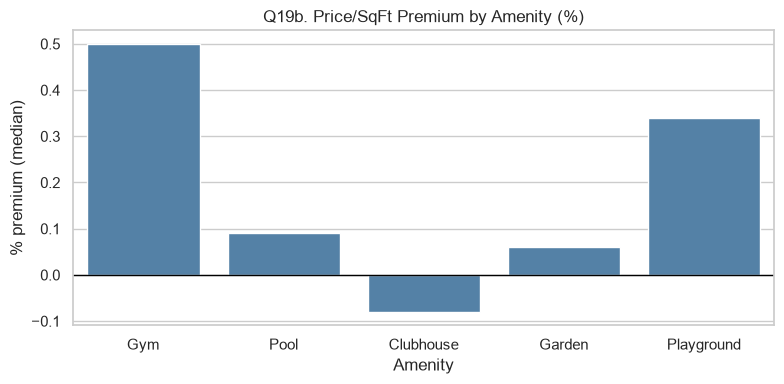

In [49]:
plt.figure(figsize=(8, 4))
sns.barplot(x=amen_tbl.index, y=amen_tbl["Premium_%"], color="steelblue")
plt.axhline(0, color="black", lw=1)
plt.title("Q19b. Price/SqFt Premium by Amenity (%)"); plt.ylabel("% premium (median)")
plt.tight_layout(); save("q19b_amenity_premium"); plt.show()

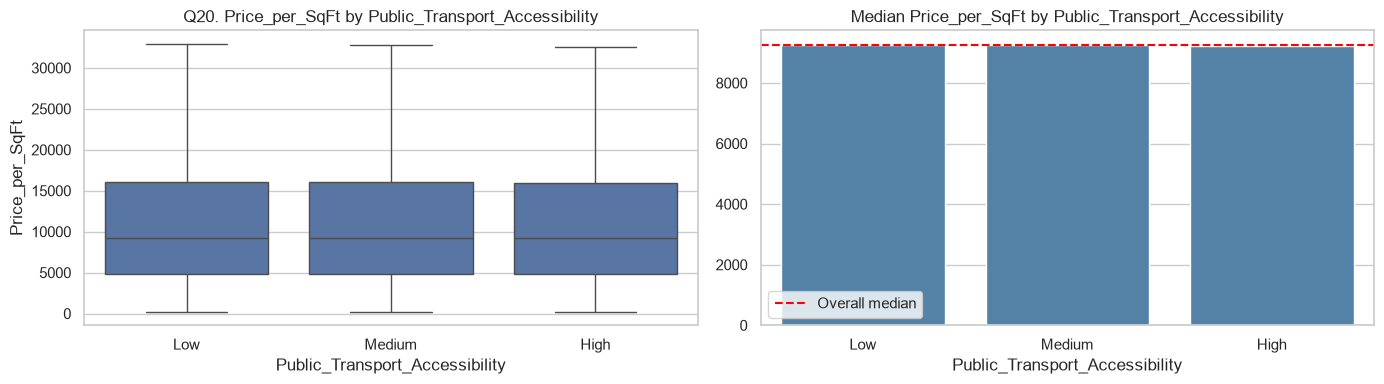

Kruskal H=1.0, p=0.6111 → not significant  |  median spread = 0.7%
Spearman (Low→High trend) ρ=-0.0018, p=0.3617


In [50]:
category_effect("Public_Transport_Accessibility", order=["Low", "Medium", "High"], qnum="Q20.")

# Transport is ordinal → test for a trend too
trans_rank = df["Public_Transport_Accessibility"].map({"Low": 0, "Medium": 1, "High": 2})
rho, p = stats.spearmanr(trans_rank, df["Price_per_SqFt"])
print(f"Spearman (Low→High trend) ρ={rho:.4f}, p={p:.4f}")

In [51]:
summary = pd.DataFrame([
    ("Q3",  "Property_Type",    "Price_per_SqFt"),
    ("Q6",  "State",            "Price_per_SqFt"),
    ("Q7",  "City",             "Price_in_Lakhs"),
    ("Q12", "Nearby_Schools",   "Price_per_SqFt"),
    ("Q13", "Nearby_Hospitals", "Price_per_SqFt"),
    ("Q14", "Furnished_Status", "Price_in_Lakhs"),
    ("Q15", "Facing",           "Price_per_SqFt"),
    ("Q18", "Parking_Space",    "Price_in_Lakhs"),
    ("Q19", "Amenity_Count",    "Price_per_SqFt"),
    ("Q20", "Public_Transport_Accessibility", "Price_per_SqFt"),
], columns=["Q", "Feature", "Target"])

def test_row(r):
    groups = [g[r.Target].values for _, g in df.groupby(r.Feature)]
    _, p = stats.kruskal(*groups)
    med = df.groupby(r.Feature)[r.Target].median()
    return pd.Series({"p_value": p, "Spread_%": (med.max() - med.min()) / df[r.Target].median() * 100})

summary[["p_value", "Spread_%"]] = summary.apply(test_row, axis=1)
summary["Significant"] = np.where(summary["p_value"] < 0.05, "Yes", "No")
summary.round(4)

,Q,Feature,Target,p_value,Spread_%,Significant
0,Q3,Property_Type,Price_per_SqFt,0.02,1.24,Yes
1,Q6,State,Price_per_SqFt,0.58,3.24,No
2,Q7,City,Price_in_Lakhs,0.23,4.55,No
3,Q12,Nearby_Schools,Price_per_SqFt,0.16,2.25,No
4,Q13,Nearby_Hospitals,Price_per_SqFt,0.06,2.38,No
5,Q14,Furnished_Status,Price_in_Lakhs,0.61,0.25,No
6,Q15,Facing,Price_per_SqFt,0.35,0.96,No
7,Q18,Parking_Space,Price_in_Lakhs,0.57,0.39,No
8,Q19,Amenity_Count,Price_per_SqFt,0.54,0.94,No
9,Q20,Public_Transport_Accessibility,Price_per_SqFt,0.61,0.69,No


In [52]:
alpha = 0.05
n_tests = len(summary)
summary["Bonferroni_Sig"] = np.where(summary["p_value"] < alpha / n_tests, "Yes", "No")

print(f"Corrected threshold: {alpha}/{n_tests} = {alpha/n_tests:.4f}")
summary.round(4)

Corrected threshold: 0.05/10 = 0.0050


,Q,Feature,Target,p_value,Spread_%,Significant,Bonferroni_Sig
0,Q3,Property_Type,Price_per_SqFt,0.02,1.24,Yes,No
1,Q6,State,Price_per_SqFt,0.58,3.24,No,No
2,Q7,City,Price_in_Lakhs,0.23,4.55,No,No
3,Q12,Nearby_Schools,Price_per_SqFt,0.16,2.25,No,No
4,Q13,Nearby_Hospitals,Price_per_SqFt,0.06,2.38,No,No
5,Q14,Furnished_Status,Price_in_Lakhs,0.61,0.25,No,No
6,Q15,Facing,Price_per_SqFt,0.35,0.96,No,No
7,Q18,Parking_Space,Price_in_Lakhs,0.57,0.39,No,No
8,Q19,Amenity_Count,Price_per_SqFt,0.54,0.94,No,No
9,Q20,Public_Transport_Accessibility,Price_per_SqFt,0.61,0.69,No,No


## EDA Conclusion
- All 20 brief questions analysed; 10 feature→price relationships tested (Kruskal-Wallis / Mann-Whitney / χ²).
- After Bonferroni correction, **no feature has a significant effect on price**; all group spreads are < 5%.
- Features are mutually independent (Spearman |ρ| ≈ 0), except derived pairs (Age↔Year_Built, PPS↔Price/Size) and Floor_No↔Total_Floors (created by our capping).
- Distributions are uniform and category splits near-perfect → the dataset is synthetic.
- **Implication:** Good_Investment and Future_Price must be rule-based targets. Models will learn the scoring rules, not market patterns.

# Phase 4 — Feature Engineering & Target Creation

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")

PROJECT_ROOT = Path.cwd().parent
FIG_DIR = PROJECT_ROOT / "docs" / "figures"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

df = pd.read_csv(DATA_PROCESSED / "india_housing_cleaned.csv")
SEED = 42
print(df.shape)

def save(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

(250000, 33)


In [54]:
df["Transport_Score"] = df["Public_Transport_Accessibility"].map({"Low": 0, "Medium": 1, "High": 2})
df["Furnish_Score"] = df["Furnished_Status"].map({"Unfurnished": 0, "Semi-furnished": 1, "Furnished": 2})

assert df[["Transport_Score", "Furnish_Score"]].isnull().sum().sum() == 0
df[["Public_Transport_Accessibility", "Transport_Score", "Furnished_Status", "Furnish_Score"]].drop_duplicates().head(6)

,Public_Transport_Accessibility,Transport_Score,Furnished_Status,Furnish_Score
0,High,2,Furnished,2
1,Low,0,Unfurnished,0
2,Low,0,Semi-furnished,1
7,High,2,Unfurnished,0
12,Medium,1,Semi-furnished,1
13,Medium,1,Unfurnished,0


In [55]:
# Normalise counts (1–10) → 0–1
df["School_Density_Score"] = (df["Nearby_Schools"] - 1) / 9
df["Hospital_Density_Score"] = (df["Nearby_Hospitals"] - 1) / 9

# Infrastructure (0–10). Transport weighted highest: connectivity is the
# strongest real-world appreciation driver. Weights = documented assumption.
INFRA_W = {"school": 0.3, "hospital": 0.3, "transport": 0.4}
df["Infrastructure_Score"] = 10 * (
    INFRA_W["school"] * df["School_Density_Score"]
    + INFRA_W["hospital"] * df["Hospital_Density_Score"]
    + INFRA_W["transport"] * df["Transport_Score"] / 2
)

df["Infrastructure_Score"].describe()

count   250000.000
mean         5.003
std          2.122
min          0.000
25%          3.333
50%          5.000
75%          6.667
max         10.000
Name: Infrastructure_Score, dtype: float64

In [56]:
TIER_1 = ["Mumbai", "New Delhi", "Dwarka", "Bangalore", "Chennai", "Hyderabad",
          "Kolkata", "Pune", "Ahmedabad", "Gurgaon", "Noida"]
TIER_3 = ["Gaya", "Silchar", "Bilaspur", "Haridwar", "Durgapur",
          "Jamshedpur", "Cuttack", "Warangal", "Jodhpur", "Amritsar"]

df["City_Tier"] = np.select(
    [df["City"].isin(TIER_1), df["City"].isin(TIER_3)], [1, 3], default=2
)

print(df["City_Tier"].value_counts().sort_index())
print("\nTier 2 cities:", sorted(df.loc[df["City_Tier"] == 2, "City"].unique()))

City_Tier
1     62572
2    124586
3     62842
Name: count, dtype: int64

Tier 2 cities: ['Bhopal', 'Bhubaneswar', 'Coimbatore', 'Dehradun', 'Faridabad', 'Guwahati', 'Indore', 'Jaipur', 'Kochi', 'Lucknow', 'Ludhiana', 'Mangalore', 'Mysore', 'Nagpur', 'Patna', 'Raipur', 'Ranchi', 'Surat', 'Trivandrum', 'Vijayawada', 'Vishakhapatnam']


In [57]:
df["Floor_Ratio"] = (df["Floor_No"] / df["Total_Floors"]).round(3)       # 0 = ground, 1 = top
df["Is_New"] = (df["Age_of_Property"] <= 5).astype(int)
df["Amenity_Score"] = df["Amenity_Count"] / 5

# Relative value: how expensive vs other properties in the SAME city
city_median_pps = df.groupby("City")["Price_per_SqFt"].transform("median")
df["PPS_vs_City"] = (df["Price_per_SqFt"] / city_median_pps).round(3)    # <1 = cheaper than city median

df[["Floor_Ratio", "Is_New", "Amenity_Score", "PPS_vs_City"]].describe()

,Floor_Ratio,Is_New,Amenity_Score,PPS_vs_City
count,250000.000,250000.000,250000.000,250000.000
mean,0.733,0.118,0.600,1.412
std,0.336,0.323,0.283,1.414
min,0.000,0.000,0.200,0.021
25%,0.467,0.000,0.400,0.520
50%,0.964,0.000,0.600,1.000
75%,1.000,0.000,0.800,1.729
max,1.000,1.000,1.000,10.893


In [58]:
rng = np.random.default_rng(SEED)

TIER_BASE = {1: 0.06, 2: 0.08, 3: 0.05}            # T2 = emerging growth, T1 = mature, T3 = low demand
TYPE_ADJ = {"Apartment": 0.0, "Independent House": 0.0025, "Villa": 0.005}

df["Appreciation_Rate"] = (
    df["City_Tier"].map(TIER_BASE)
    + df["Property_Type"].map(TYPE_ADJ)
    + (df["Infrastructure_Score"] / 10 - 0.5) * 0.02                      # ±1% for infra
    + (1 - df["Is_Ready_To_Move"]) * 0.01                                 # +1% under-construction
    - np.clip(df["Age_of_Property"] - 10, 0, None) * 0.0005               # depreciation after 10 yrs
    + rng.normal(0, 0.01, len(df))                                        # unobserved market factors
)

df["Future_Price_5Y"] = (df["Price_in_Lakhs"] * (1 + df["Appreciation_Rate"]) ** 5).round(2)

print(df["Appreciation_Rate"].describe())
print("\nMean rate by tier:\n", df.groupby("City_Tier")["Appreciation_Rate"].mean().round(4))

count   250000.000
mean         0.070
std          0.018
min         -0.006
25%          0.057
50%          0.071
75%          0.084
max          0.144
Name: Appreciation_Rate, dtype: float64

Mean rate by tier:
 City_Tier
1   0.063
2   0.083
3   0.053
Name: Appreciation_Rate, dtype: float64


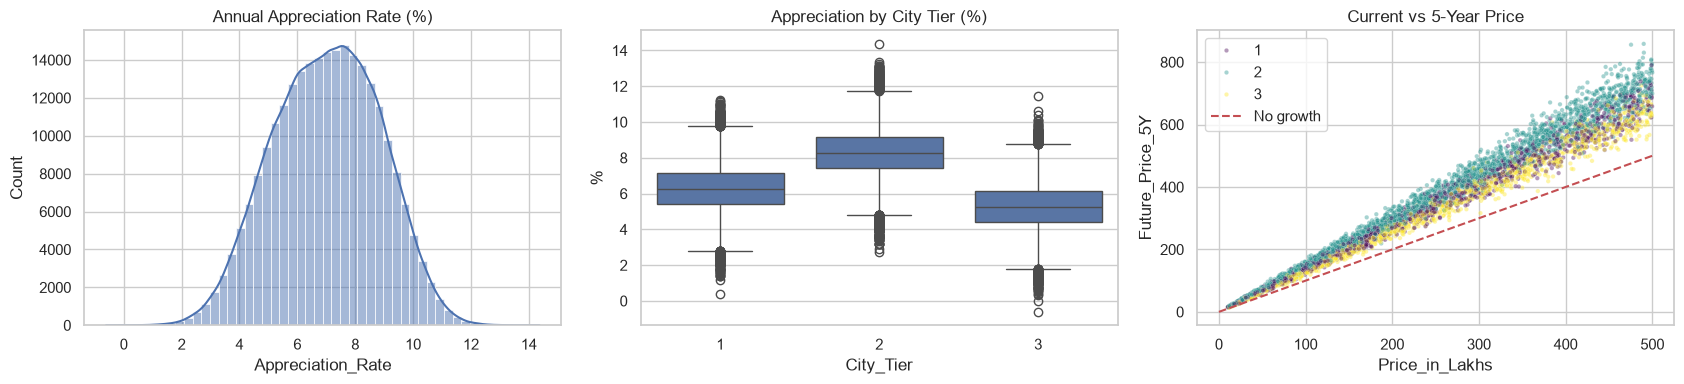

In [59]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

sns.histplot(df["Appreciation_Rate"] * 100, bins=50, kde=True, ax=ax[0])
ax[0].set_title("Annual Appreciation Rate (%)")

sns.boxplot(data=df, x="City_Tier", y=df["Appreciation_Rate"] * 100, ax=ax[1])
ax[1].set_title("Appreciation by City Tier (%)"); ax[1].set_ylabel("%")

sample = df.sample(5000, random_state=SEED)
sns.scatterplot(data=sample, x="Price_in_Lakhs", y="Future_Price_5Y", hue="City_Tier",
                alpha=0.4, s=10, palette="viridis", ax=ax[2])
ax[2].plot([0, 500], [0, 500], "r--", label="No growth")
ax[2].set_title("Current vs 5-Year Price"); ax[2].legend()

plt.tight_layout(); save("fe_regression_target"); plt.show()

In [60]:
criteria = pd.DataFrame({
    "C1_Underpriced":   df["PPS_vs_City"] <= 1,                                   # cheaper than city median
    "C2_High_Growth":   df["Appreciation_Rate"] >= df["Appreciation_Rate"].median(),
    "C3_Family_Size":   df["BHK"] >= 3,
    "C4_Ready":         df["Is_Ready_To_Move"] == 1,
    "C5_Good_Infra":    df["Infrastructure_Score"] >= df["Infrastructure_Score"].median(),
    "C6_Amenities":     df["Amenity_Count"] >= 3,
}).astype(int)

df["GI_Score"] = criteria.sum(axis=1)
GI_THRESHOLD = 4
df["Good_Investment"] = (df["GI_Score"] >= GI_THRESHOLD).astype(int)

print("Criteria pass rate:\n", criteria.mean().round(3))
print("\nScore distribution:\n", df["GI_Score"].value_counts().sort_index())
print(f"\nGood_Investment (score ≥ {GI_THRESHOLD}): {df['Good_Investment'].mean():.1%} positive")

Criteria pass rate:
 C1_Underpriced   0.500
C2_High_Growth   0.500
C3_Family_Size   0.600
C4_Ready         0.500
C5_Good_Infra    0.531
C6_Amenities     0.600
dtype: float64

Score distribution:
 GI_Score
0     2221
1    16367
2    49028
3    77832
4    68405
5    30593
6     5554
Name: count, dtype: int64

Good_Investment (score ≥ 4): 41.8% positive


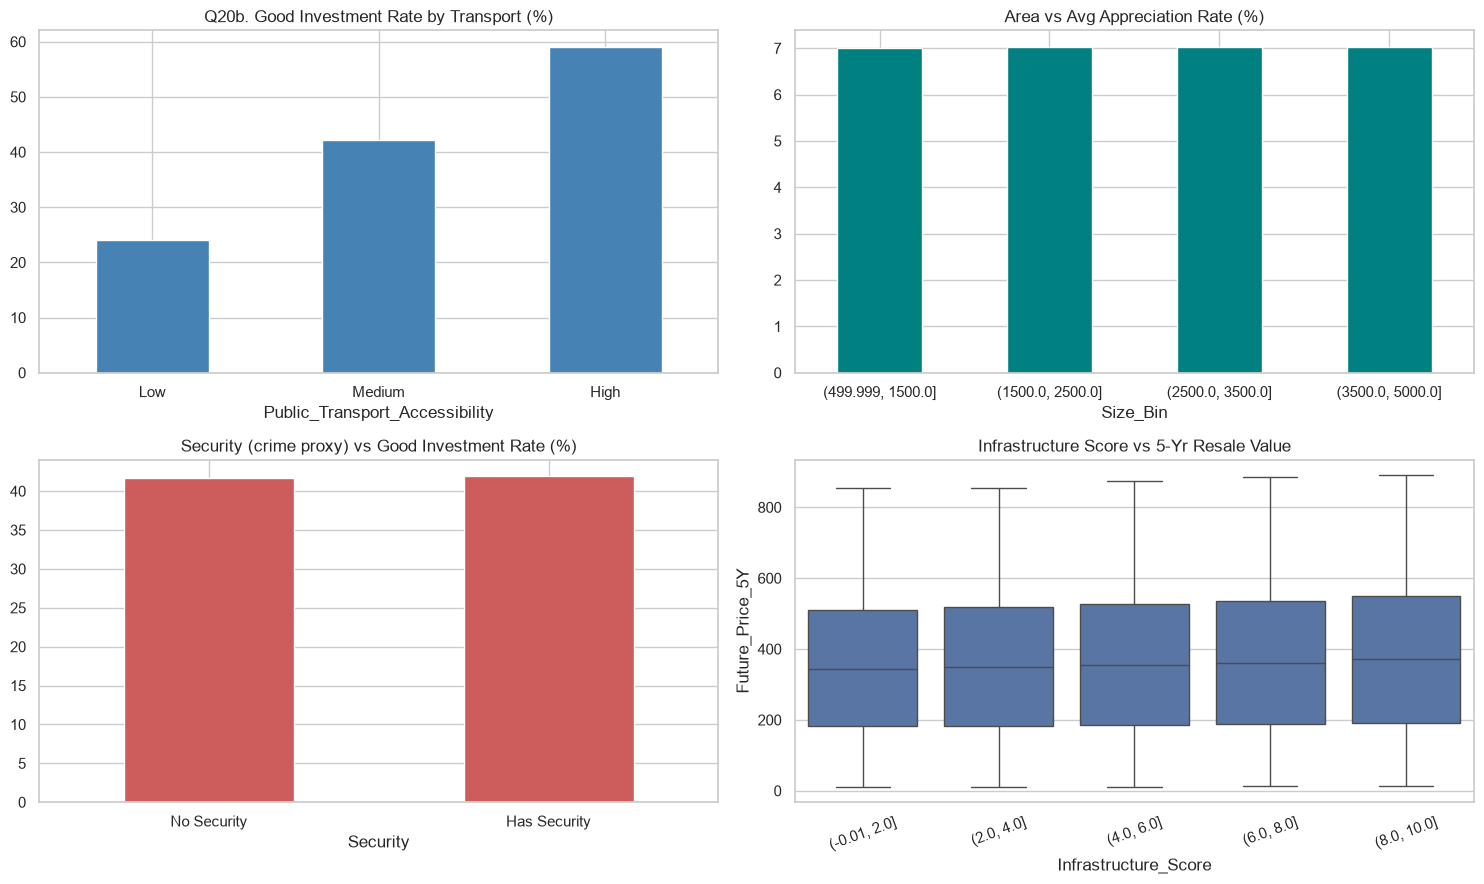

Top 5 projected growth cities (%):
 City
Patna        8.310
Bhopal       8.300
Surat        8.300
Trivandrum   8.290
Ranchi       8.290
Name: Appreciation_Rate, dtype: float64


In [61]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# (a) Transport → investment potential (Q20b)
gi_trans = df.groupby("Public_Transport_Accessibility")["Good_Investment"].mean().reindex(["Low", "Medium", "High"]) * 100
gi_trans.plot(kind="bar", ax=ax[0, 0], color="steelblue", rot=0)
ax[0, 0].set_title("Q20b. Good Investment Rate by Transport (%)")

# (b) Area vs investment return
df["Size_Bin"] = pd.cut(df["Size_in_SqFt"], bins=[500, 1500, 2500, 3500, 5000], include_lowest=True)
df.groupby("Size_Bin", observed=True)["Appreciation_Rate"].mean().mul(100).plot(kind="bar", ax=ax[0, 1], color="teal", rot=0)
ax[0, 1].set_title("Area vs Avg Appreciation Rate (%)")

# (c) Crime-rate proxy: no crime column → Security (gated/CCTV) used as proxy
df.groupby("Security")["Good_Investment"].mean().mul(100).rename({0: "No Security", 1: "Has Security"}) \
  .plot(kind="bar", ax=ax[1, 0], color="indianred", rot=0)
ax[1, 0].set_title("Security (crime proxy) vs Good Investment Rate (%)")

# (d) Infrastructure vs resale value
sns.boxplot(data=df, x=pd.cut(df["Infrastructure_Score"], 5), y="Future_Price_5Y", showfliers=False, ax=ax[1, 1])
ax[1, 1].set_title("Infrastructure Score vs 5-Yr Resale Value"); ax[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout(); save("fe_pending_eda"); plt.show()
df = df.drop(columns="Size_Bin")

# Price trend by city (projected): which cities grow fastest?
city_growth = df.groupby("City")["Appreciation_Rate"].mean().mul(100).sort_values(ascending=False)
print("Top 5 projected growth cities (%):\n", city_growth.head().round(2))

In [62]:
# Columns that must NEVER be model inputs (targets or built from targets)
LEAKAGE_COLS = ["Appreciation_Rate", "Future_Price_5Y", "Good_Investment", "GI_Score"]

# Redundant / non-model columns
DROP_COLS = [
    "ID", "Price_per_SqFt",          # PPS = Price/Size → redundant once Price & Size are inputs
    "Year_Built",                    # = 2025 − Age (ρ = −1.00)
    "Amenities",                     # replaced by Has_* flags
    "Availability_Status",           # replaced by Is_Ready_To_Move
    "Public_Transport_Accessibility", "Furnished_Status",   # replaced by ordinal scores
    "Locality", "City_Locality",     # ~12 rows/key, no price effect in EDA
    "PPS_Outlier",                   # diagnostic flag only
]

FEATURES = [c for c in df.columns if c not in LEAKAGE_COLS + DROP_COLS]
print(f"{len(FEATURES)} model features:\n", FEATURES)

df.to_csv(DATA_PROCESSED / "india_housing_features.csv", index=False)
print("\nSaved →", DATA_PROCESSED / "india_housing_features.csv", df.shape)

33 model features:
 ['State', 'City', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Parking_Space', 'Security', 'Facing', 'Owner_Type', 'Floor_Inconsistent', 'Is_Ready_To_Move', 'Has_Gym', 'Has_Pool', 'Has_Clubhouse', 'Has_Garden', 'Has_Playground', 'Amenity_Count', 'Transport_Score', 'Furnish_Score', 'School_Density_Score', 'Hospital_Density_Score', 'Infrastructure_Score', 'City_Tier', 'Floor_Ratio', 'Is_New', 'Amenity_Score', 'PPS_vs_City']

Saved → U:\AI\Labmentrix\Real-Estate-Investment-Advisor\data\processed\india_housing_features.csv (250000, 47)


# Phases 5 & 6 — Model Training + MLflow Tracking

In [68]:
import time
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             mean_squared_error, mean_absolute_error, r2_score)

warnings.filterwarnings("ignore")
logging.getLogger("mlflow").setLevel(logging.ERROR)   # silence cloudpickle warnings
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd().parent
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "docs" / "figures"
SEED = 42

print("mlflow:", mlflow.__version__)

mlflow: 3.17.2


In [69]:
df = pd.read_csv(DATA_PROCESSED / "india_housing_features.csv")

CAT_FEATURES = ["City", "Property_Type", "Facing", "Owner_Type"]
NUM_FEATURES = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Floor_No", "Total_Floors", "Age_of_Property",
    "Nearby_Schools", "Nearby_Hospitals", "Parking_Space", "Security", "Floor_Inconsistent",
    "Is_Ready_To_Move", "Has_Gym", "Has_Pool", "Has_Clubhouse", "Has_Garden", "Has_Playground",
    "Amenity_Count", "Transport_Score", "Furnish_Score", "Infrastructure_Score",
    "City_Tier", "Floor_Ratio", "Is_New", "PPS_vs_City",
]
FEATURES = CAT_FEATURES + NUM_FEATURES

X = df[FEATURES]
y_clf = df["Good_Investment"]
y_reg = df["Future_Price_5Y"]
print(f"{len(FEATURES)} features | {len(CAT_FEATURES)} categorical, {len(NUM_FEATURES)} numeric")

29 features | 4 categorical, 25 numeric


In [70]:
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_clf, y_reg, test_size=0.2, stratify=y_clf, random_state=SEED
)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
print(f"Good_Investment rate — train {yc_train.mean():.3f}, test {yc_test.mean():.3f}")

Train: 200,000 | Test: 50,000
Good_Investment rate — train 0.418, test 0.418


In [71]:
def make_preprocessor():
    """Fit inside the Pipeline → learns only from training data."""
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES),
    ])

MLFLOW_DB = (PROJECT_ROOT / "mlflow.db").as_posix()
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

def set_experiment(name):
    if mlflow.get_experiment_by_name(name) is None:
        mlflow.create_experiment(name, artifact_location=(PROJECT_ROOT / "mlruns").as_uri())
    mlflow.set_experiment(name)

print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: sqlite:///U:/AI/Labmentrix/Real-Estate-Investment-Advisor/mlflow.db


In [85]:
class ExperimentRunner:
    """Trains a model inside a Pipeline, evaluates on test set, logs everything to MLflow."""

    def __init__(self, task, experiment, X_train, y_train, X_test, y_test):
        self.task, self.experiment = task, experiment
        self.X_train, self.y_train = X_train, y_train
        self.X_test, self.y_test = X_test, y_test
        self.results, self.pipelines = [], {}

    def _metrics(self, pipe):
        y_pred = pipe.predict(self.X_test)
        if self.task == "classification":
            proba = pipe.predict_proba(self.X_test)[:, 1]
            return y_pred, {
                "accuracy": accuracy_score(self.y_test, y_pred),
                "precision": precision_score(self.y_test, y_pred, zero_division=0),
                "recall": recall_score(self.y_test, y_pred),
                "f1": f1_score(self.y_test, y_pred),
                "roc_auc": roc_auc_score(self.y_test, proba),
            }
        return y_pred, {
            "rmse": np.sqrt(mean_squared_error(self.y_test, y_pred)),
            "mae": mean_absolute_error(self.y_test, y_pred),
            "r2": r2_score(self.y_test, y_pred),
        }

    def _diagnostic_plot(self, y_pred, name):
        fig, ax = plt.subplots(figsize=(5, 4))
        if self.task == "classification":
            ConfusionMatrixDisplay(confusion_matrix(self.y_test, y_pred),
                                   display_labels=["Not Good", "Good"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
            ax.set_title(f"{name} — Confusion Matrix")
        else:
            idx = np.random.default_rng(SEED).choice(len(y_pred), 3000, replace=False)
            ax.scatter(np.asarray(self.y_test)[idx], y_pred[idx], s=5, alpha=0.4)
            lim = [0, max(self.y_test.max(), y_pred.max())]
            ax.plot(lim, lim, "r--")
            ax.set_xlabel("Actual"); ax.set_ylabel("Predicted")
            ax.set_title(f"{name} — Actual vs Predicted")
        plt.tight_layout()
        return fig

    def run(self, name, model, log_model=True):
        set_experiment(self.experiment)
        pipe = Pipeline([("pre", make_preprocessor()), ("model", model)])

        start = time.time()
        pipe.fit(self.X_train, self.y_train)
        train_time = time.time() - start

        y_pred, metrics = self._metrics(pipe)
        metrics["train_time_s"] = train_time

        with mlflow.start_run(run_name=name):
            mlflow.set_tags({"task": self.task, "model_type": type(model).__name__})
            mlflow.log_params({k: v for k, v in model.get_params().items() if v is not None})
            mlflow.log_param("n_features", len(FEATURES))
            mlflow.log_metrics(metrics)

            fig = self._diagnostic_plot(y_pred, name)
            mlflow.log_figure(fig, f"{name}_diagnostic.png")
            plt.show()

            if log_model:
                mlflow.sklearn.log_model(pipe, name="model", input_example=self.X_test.head(3),
                                         serialization_format="cloudpickle")

        self.pipelines[name] = pipe
        self.results.append({"model": name, **metrics})
        print(f"✔ {name:20s} " + "  ".join(f"{k}={v:.4f}" for k, v in metrics.items()
                                          if k != "train_time_s") + f"  ({train_time:.1f}s)")
        return pipe

    def summary(self, sort_by):
        ascending = sort_by in ("rmse", "mae")
        return pd.DataFrame(self.results).set_index("model").sort_values(sort_by, ascending=ascending)

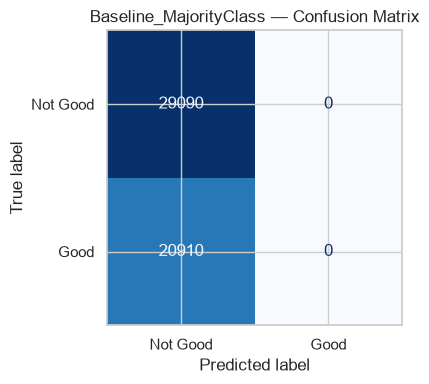

✔ Baseline_MajorityClass accuracy=0.5818  precision=0.0000  recall=0.0000  f1=0.0000  roc_auc=0.5000  (0.3s)
✔ Baseline_Fixed8pct   rmse=39.0791  mae=27.8639  r2=0.9629


In [86]:
clf_runner = ExperimentRunner("classification", "Good_Investment_Classification",
                              X_train, yc_train, X_test, yc_test)
clf_runner.run("Baseline_MajorityClass", DummyClassifier(strategy="most_frequent"), log_model=False)

reg_runner = ExperimentRunner("regression", "Future_Price_Regression",
                              X_train, yr_train, X_test, yr_test)

# Naive rule from the brief: Future = Current × (1 + 8%)^5
naive_pred = X_test["Price_in_Lakhs"] * 1.08 ** 5
naive = {"rmse": np.sqrt(mean_squared_error(yr_test, naive_pred)),
         "mae": mean_absolute_error(yr_test, naive_pred),
         "r2": r2_score(yr_test, naive_pred)}

set_experiment("Future_Price_Regression")
with mlflow.start_run(run_name="Baseline_Fixed8pct"):
    mlflow.set_tags({"task": "regression", "model_type": "rule: price x 1.08^5"})
    mlflow.log_metrics(naive)
reg_runner.results.append({"model": "Baseline_Fixed8pct", **naive})
print("✔ Baseline_Fixed8pct   " + "  ".join(f"{k}={v:.4f}" for k, v in naive.items()))

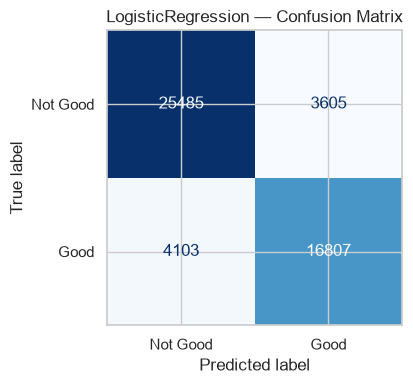

✔ LogisticRegression   accuracy=0.8458  precision=0.8234  recall=0.8038  f1=0.8135  roc_auc=0.9289  (1.0s)


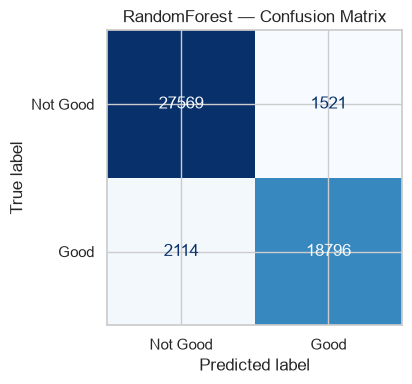

✔ RandomForest         accuracy=0.9273  precision=0.9251  recall=0.8989  f1=0.9118  roc_auc=0.9854  (5.5s)


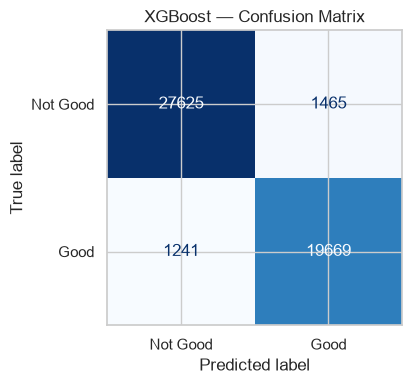

✔ XGBoost              accuracy=0.9459  precision=0.9307  recall=0.9407  f1=0.9356  roc_auc=0.9908  (2.5s)


,accuracy,precision,recall,f1,roc_auc,train_time_s
model,,,,,,
XGBoost,0.946,0.931,0.941,0.936,0.991,2.515
RandomForest,0.927,0.925,0.899,0.912,0.985,5.528
LogisticRegression,0.846,0.823,0.804,0.814,0.929,1.012
Baseline_MajorityClass,0.582,0.000,0.000,0.000,0.500,0.315


In [87]:
clf_runner.run("LogisticRegression", LogisticRegression(max_iter=1000, random_state=SEED))

clf_runner.run("RandomForest", RandomForestClassifier(
    n_estimators=100, max_depth=15, min_samples_leaf=5, n_jobs=-1, random_state=SEED))

clf_runner.run("XGBoost", XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=SEED, eval_metric="logloss"))

clf_runner.summary("f1").round(4)

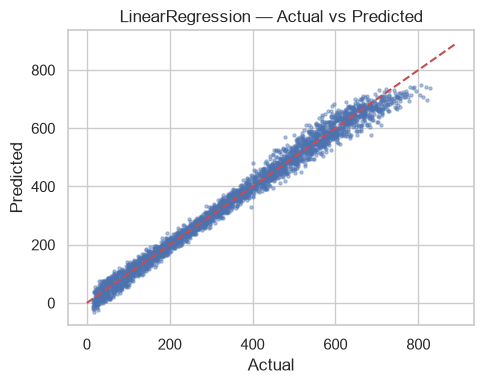

✔ LinearRegression     rmse=23.8993  mae=18.2758  r2=0.9861  (1.2s)


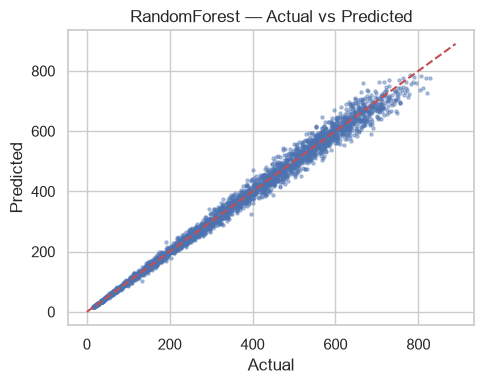

✔ RandomForest         rmse=19.7833  mae=13.7980  r2=0.9905  (21.7s)


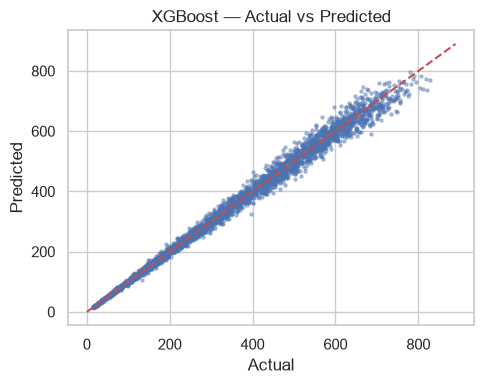

✔ XGBoost              rmse=19.4256  mae=13.5227  r2=0.9908  (1.9s)


,rmse,mae,r2,train_time_s
model,,,,
XGBoost,19.426,13.523,0.991,1.915
RandomForest,19.783,13.798,0.991,21.718
LinearRegression,23.899,18.276,0.986,1.181
Baseline_Fixed8pct,39.079,27.864,0.963,NaN


In [88]:
reg_runner.run("LinearRegression", LinearRegression())

reg_runner.run("RandomForest", RandomForestRegressor(
    n_estimators=100, max_depth=15, min_samples_leaf=5, n_jobs=-1, random_state=SEED))

reg_runner.run("XGBoost", XGBRegressor(
    n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=SEED))

reg_runner.summary("rmse").round(4)

In [89]:
# The noise term N(0, 1%) in Appreciation_Rate can't be predicted from any feature.
# Its effect on Future_Price ≈ Price × 5(1+r)^4 × 0.01 → that's the lowest RMSE any model can reach.
price = X_test["Price_in_Lakhs"].values
r_mean = df["Appreciation_Rate"].mean()
floor = np.sqrt(np.mean((price * 5 * (1 + r_mean) ** 4 * 0.01) ** 2))

best_rmse = reg_runner.summary("rmse")["rmse"].iloc[0]
print(f"Irreducible RMSE floor ≈ ₹{floor:.1f} L")
print(f"Best model RMSE        = ₹{best_rmse:.1f} L  ({(best_rmse/floor - 1)*100:.1f}% above floor)")

Irreducible RMSE floor ≈ ₹19.1 L
Best model RMSE        = ₹19.4 L  (1.7% above floor)


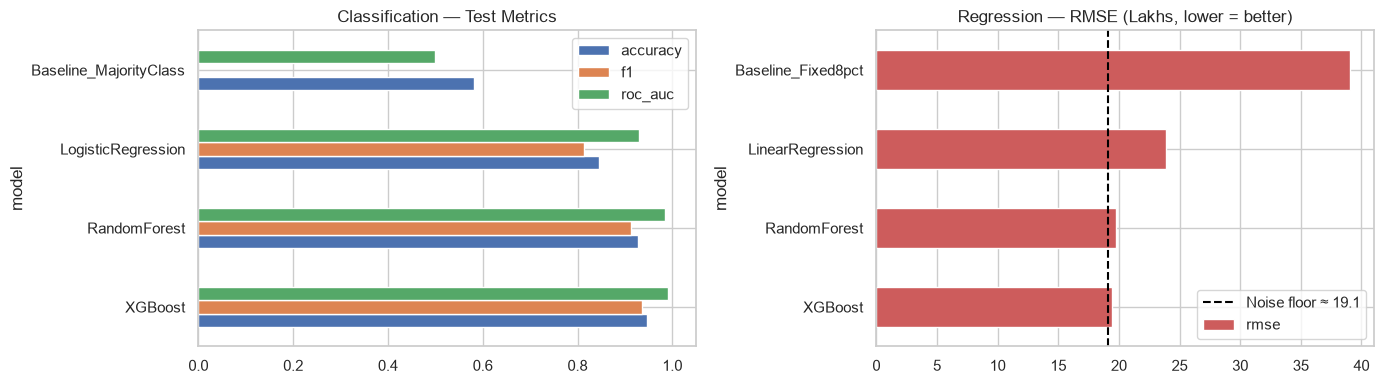

In [90]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

clf_sum = clf_runner.summary("f1")
clf_sum[["accuracy", "f1", "roc_auc"]].plot(kind="barh", ax=ax[0])
ax[0].set_title("Classification — Test Metrics"); ax[0].set_xlim(0, 1.05)

reg_sum = reg_runner.summary("rmse")
reg_sum["rmse"].plot(kind="barh", ax=ax[1], color="indianred")
ax[1].axvline(floor, color="black", ls="--", label=f"Noise floor ≈ {floor:.1f}")
ax[1].set_title("Regression — RMSE (Lakhs, lower = better)"); ax[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

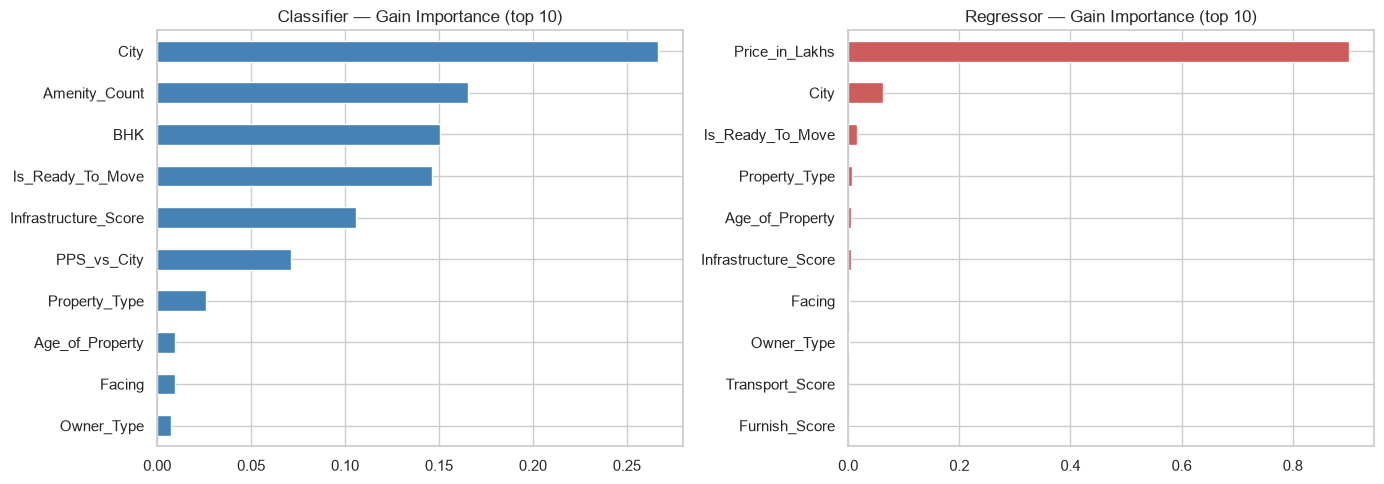

In [91]:
def grouped_importance(pipe):
    """XGBoost gain importance, with one-hot columns (City_Mumbai, ...) summed back to 'City'."""
    names = pipe.named_steps["pre"].get_feature_names_out()          # e.g. 'cat__City_Pune', 'num__BHK'
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
    orig = [n.split("__", 1)[1] for n in names]
    orig = [next((c for c in CAT_FEATURES if o.startswith(c + "_")), o) for o in orig]
    return imp.groupby(orig).sum().sort_values(ascending=False)

clf_gain = grouped_importance(clf_runner.pipelines["XGBoost"])
reg_gain = grouped_importance(reg_runner.pipelines["XGBoost"])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
clf_gain.head(10)[::-1].plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Classifier — Gain Importance (top 10)")
reg_gain.head(10)[::-1].plot(kind="barh", ax=ax[1], color="indianred")
ax[1].set_title("Regressor — Gain Importance (top 10)")
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_importance_gain.png", dpi=120, bbox_inches="tight"); plt.show()

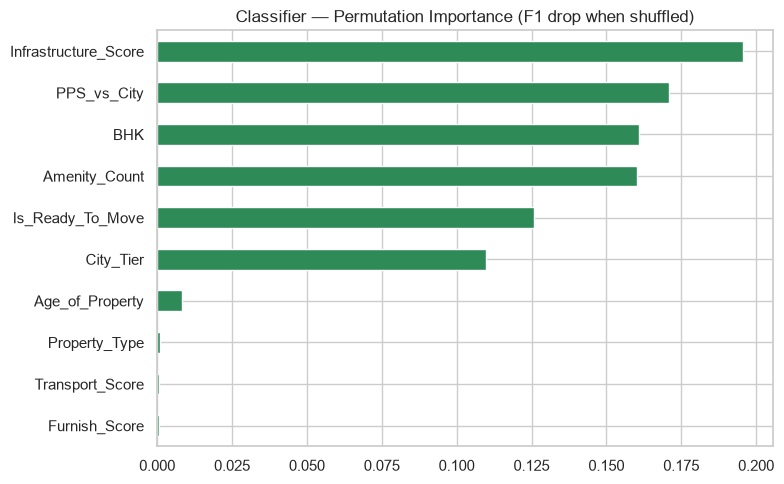

Infrastructure_Score   0.196
PPS_vs_City            0.171
BHK                    0.161
Amenity_Count          0.160
Is_Ready_To_Move       0.126
City_Tier              0.110
Age_of_Property        0.008
Property_Type          0.001
Transport_Score        0.001
Furnish_Score          0.001
dtype: float64

In [92]:
from sklearn.inspection import permutation_importance

idx = X_test.sample(10_000, random_state=SEED).index      # 10k sample keeps it ~10s
perm = permutation_importance(clf_runner.pipelines["XGBoost"], X_test.loc[idx], yc_test.loc[idx],
                              scoring="f1", n_repeats=3, random_state=SEED, n_jobs=-1)

clf_perm = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
clf_perm.head(10)[::-1].plot(kind="barh", color="seagreen")
plt.title("Classifier — Permutation Importance (F1 drop when shuffled)")
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_importance_permutation.png", dpi=120, bbox_inches="tight"); plt.show()

clf_perm.head(10).round(4)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best CV F1: 0.9378
Best params: {'colsample_bytree': np.float64(0.883), 'learning_rate': np.float64(0.033), 'max_depth': 4, 'min_child_weight': 8, 'n_estimators': 493, 'subsample': np.float64(0.7)}


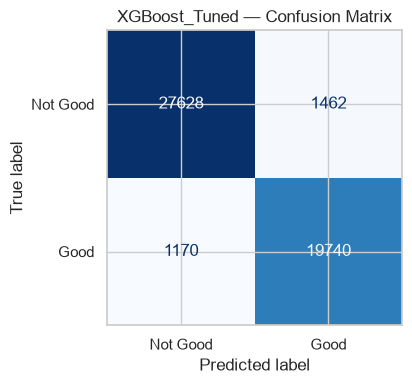

✔ XGBoost_Tuned        accuracy=0.9474  precision=0.9310  recall=0.9440  f1=0.9375  roc_auc=0.9910  (3.5s)


,accuracy,precision,recall,f1,roc_auc,train_time_s
model,,,,,,
XGBoost_Tuned,0.947,0.931,0.944,0.938,0.991,3.458
XGBoost,0.946,0.931,0.941,0.936,0.991,2.515
RandomForest,0.927,0.925,0.899,0.912,0.985,5.528
LogisticRegression,0.846,0.823,0.804,0.814,0.929,1.012
Baseline_MajorityClass,0.582,0.000,0.000,0.000,0.500,0.315


In [93]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

# Tune on a 50k stratified sample — 45 fits on 200k rows would take ~4× longer for no real gain
X_tune, _, y_tune, _ = train_test_split(X_train, yc_train, train_size=50_000,
                                        stratify=yc_train, random_state=SEED)

search = RandomizedSearchCV(
    Pipeline([("pre", make_preprocessor()),
              ("model", XGBClassifier(n_jobs=-1, random_state=SEED, eval_metric="logloss"))]),
    param_distributions={
        "model__n_estimators":     randint(200, 600),
        "model__max_depth":        randint(3, 10),
        "model__learning_rate":    uniform(0.03, 0.17),     # 0.03 – 0.20
        "model__subsample":        uniform(0.7, 0.3),       # 0.7 – 1.0
        "model__colsample_bytree": uniform(0.6, 0.4),       # 0.6 – 1.0
        "model__min_child_weight": randint(1, 10),
    },
    n_iter=15, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
    scoring="f1", n_jobs=1, random_state=SEED, verbose=1,
)
search.fit(X_tune, y_tune)

best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print(f"Best CV F1: {search.best_score_:.4f}")
print("Best params:", {k: round(v, 3) if isinstance(v, float) else v for k, v in best_params.items()})

# Refit on full training set + log to MLflow via the runner
clf_runner.run("XGBoost_Tuned", XGBClassifier(**best_params, n_jobs=-1, random_state=SEED, eval_metric="logloss"))
clf_runner.summary("f1").round(4)

In [94]:
from mlflow.tracking import MlflowClient

def register_best(experiment, run_name, model_name, alias="champion"):
    runs = mlflow.search_runs(experiment_names=[experiment],
                              filter_string=f"tags.mlflow.runName = '{run_name}'",
                              order_by=["start_time DESC"], max_results=1)
    run_id = runs.iloc[0]["run_id"]
    mv = mlflow.register_model(f"runs:/{run_id}/model", model_name)
    MlflowClient().set_registered_model_alias(model_name, alias, mv.version)
    print(f"✔ {model_name} v{mv.version} → @{alias}  (run {run_id[:8]})")

CLF_NAME = "RealEstate_GoodInvestment_Classifier"
REG_NAME = "RealEstate_FuturePrice_Regressor"

register_best("Good_Investment_Classification", "XGBoost_Tuned", CLF_NAME)
register_best("Future_Price_Regression", "XGBoost", REG_NAME)

# Prove the registry works: reload and re-score
clf_loaded = mlflow.sklearn.load_model(f"models:/{CLF_NAME}@champion")
reg_loaded = mlflow.sklearn.load_model(f"models:/{REG_NAME}@champion")
print("\nReloaded classifier accuracy:", round(accuracy_score(yc_test, clf_loaded.predict(X_test)), 4))
print("Reloaded regressor RMSE:     ", round(np.sqrt(mean_squared_error(yr_test, reg_loaded.predict(X_test))), 2))

✔ RealEstate_GoodInvestment_Classifier v2 → @champion  (run 78373237)
✔ RealEstate_FuturePrice_Regressor v2 → @champion  (run efb7b6d7)


Registered model 'RealEstate_GoodInvestment_Classifier' already exists. Creating a new version of this model...
Created version '2' of model 'RealEstate_GoodInvestment_Classifier'.
Registered model 'RealEstate_FuturePrice_Regressor' already exists. Creating a new version of this model...
Created version '2' of model 'RealEstate_FuturePrice_Regressor'.



Reloaded classifier accuracy: 0.9474
Reloaded regressor RMSE:      19.43


In [95]:
import json
import joblib

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(clf_loaded, MODEL_DIR / "good_investment_clf.joblib", compress=3)
joblib.dump(reg_loaded, MODEL_DIR / "future_price_reg.joblib", compress=3)

# Everything the app needs to build features EXACTLY like training did
clf_best = clf_runner.summary("f1").loc["XGBoost_Tuned"]
reg_best = reg_runner.summary("rmse").loc["XGBoost"]

metadata = {
    "cat_features": CAT_FEATURES,
    "num_features": NUM_FEATURES,
    "city_median_pps": df.groupby("City")["Price_per_SqFt"].median().round(2).to_dict(),
    "city_tier": df.groupby("City")["City_Tier"].first().astype(int).to_dict(),
    "city_to_state": df.groupby("City")["State"].first().to_dict(),
    "options": {c: sorted(df[c].unique().tolist()) for c in ["City", "Property_Type", "Facing", "Owner_Type"]},
    "metrics": {
        "classifier": {k: round(float(clf_best[k]), 4) for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
        "regressor":  {k: round(float(reg_best[k]), 4) for k in ["rmse", "mae", "r2"]},
        "regression_noise_floor": round(float(floor), 2),
    },
    "permutation_importance": clf_perm.head(10).round(4).to_dict(),
}
with open(MODEL_DIR / "app_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

for p in sorted(MODEL_DIR.iterdir()):
    print(f"{p.name:30s} {p.stat().st_size / 1e6:.2f} MB")

app_metadata.json              0.01 MB
future_price_reg.joblib        0.45 MB
good_investment_clf.joblib     0.20 MB


In [96]:
import sklearn, xgboost, streamlit, joblib
for lib in [pd, np, sklearn, xgboost, mlflow, joblib, streamlit]:
    print(f"{lib.__name__}=={lib.__version__}")

pandas==2.3.3
numpy==2.3.4
sklearn==1.6.1
xgboost==3.2.0
mlflow==3.17.2
joblib==1.5.2
streamlit==1.38.0


# Phase 7 — Streamlit App

In [97]:
# Features CSV ≈ 76 MB (GitHub warns >50 MB, slow to load). App needs only 18 columns.
APP_COLS = ["State", "City", "Locality", "Property_Type", "BHK", "Size_in_SqFt", "Price_in_Lakhs",
            "Price_per_SqFt", "Age_of_Property", "Furnished_Status", "Public_Transport_Accessibility",
            "Amenity_Count", "Infrastructure_Score", "City_Tier", "Availability_Status",
            "Appreciation_Rate", "Future_Price_5Y", "Good_Investment"]

app_df = df[APP_COLS].copy()
for c in app_df.select_dtypes(include="object").columns:
    app_df[c] = app_df[c].astype("category")

out = DATA_PROCESSED / "app_data.parquet"
app_df.to_parquet(out, index=False, compression="zstd")
print(f"Saved {out.name}: {out.stat().st_size / 1e6:.1f} MB")

Saved app_data.parquet: 7.2 MB
